<a href="https://colab.research.google.com/github/Noelsip/final-task/blob/main/Tugas_Akhir_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Pengaruh *Cyclical Learning Rate* terhadap Model CNN dalam Klasifikasi Citra Sintetis AI

**Dataset:** CIFAKE
****
**Kelas:** REAL dan FAKE

**Model:** *Covolution Neural Network*

**Strategi Learning Rate:** *Fixed Learning Rate* dan *Cyclical Learning Rate*

## Instalasi Pustaka

In [ ]:
import os
import gc
import math
import random
import platform
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Library Berhasil dimuat.")
print("TensorFlow : ", tf.__version__)
print("Numpy      : ", np.__version__)
print("Pandas     : ", pd.__version__)

Library Berhasil dimuat.
TensorFlow :  2.21.0
Numpy      :  2.1.3
Pandas     :  2.2.3


# Lingkungan Eksperimen

In [ ]:
# Mengimpor modul sistem Python.
import sys

# Mengimpor modul informasi sistem.
import platform

# Mengambil daftar GPU yang tersedia.
gpu_devices = tf.config.list_physical_devices("GPU")

# Mengambil informasi GPU dari NVIDIA.
gpu_info = os.popen(
    "nvidia-smi --query-gpu=name,memory.total "
    "--format=csv,noheader"
).read().strip()

# Menampilkan judul lingkungan eksperimen.
print("LINGKUNGAN EKSPERIMEN\n")

# Menampilkan platform penelitian.
print("Platform           : Google Colaboratory")

# Menampilkan informasi prosesor.
print(
    f"Prosesor           : "
    f"{platform.processor()}"
)

# Menampilkan informasi GPU.
print(
    f"GPU                : "
    f"{gpu_info if gpu_info else 'Tidak terdeteksi'}"
)

# Menampilkan informasi RAM sistem.
ram_info = os.popen("free -h").read()

# Menampilkan informasi RAM.
print("\nInformasi RAM:")
print(ram_info)

# Menampilkan versi Python.
print(
    f"Python             : "
    f"{sys.version.split()[0]}"
)

# Menampilkan versi TensorFlow.
print(
    f"TensorFlow         : "
    f"{tf.__version__}"
)

# Menampilkan versi NumPy.
print(
    f"NumPy              : "
    f"{np.__version__}"
)

# Menampilkan versi Pandas.
print(
    f"Pandas             : "
    f"{pd.__version__}"
)

# Menampilkan versi Matplotlib.
print(
    f"Matplotlib         : "
    f"{plt.matplotlib.__version__}"
)

# Mengimpor scikit-learn untuk mengambil versinya.
import sklearn

# Menampilkan versi scikit-learn.
print(
    f"scikit-learn       : "
    f"{sklearn.__version__}"
)

LINGKUNGAN EKSPERIMEN

Platform           : Google Colaboratory
Prosesor           : x86_64
GPU                : Tidak terdeteksi

Informasi RAM:
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.7Gi       7.9Gi       2.7Mi       3.3Gi        10Gi
Swap:             0B          0B          0B

Python             : 3.13.16
TensorFlow         : 2.21.0
NumPy              : 2.1.3
Pandas             : 2.2.3
Matplotlib         : 3.10.0
scikit-learn       : 1.6.1


## Konfigurasi Eksperimen dan Reproducibility

In [ ]:
SEED = 1

# Menerapkan koefisien weight decay untuk setiap bobot lapisan
WEIGHT_DECAY =   1e-5

# Menerapkan proporsi neuron yang dinonaktifkan oleh dropout
DROPOUT_RATE = 0.5

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
  tf.config.experimental.enable_op_determinism()
  DETERMINISTIC_ENABLED = True
except Exception as e:
  DETERMINISTIC_ENABLED = False
  print("Peringatan Determinism: ", e)

# Datase
DATASET_ROOT = Path("/content/cifake_data")
TRAIN_DIR = DATASET_ROOT / "train"
TEST_DIR = DATASET_ROOT / "test"

CLASS_NAMES = ["REAL" , "FAKE"]
CLASS_TO_LABEL = {
    "REAL": 0,
    "FAKE": 1
}

# Konfigurasi Citra
IMG_HEIGHT = 32
IMG_WIDTH = 32
IMG_CHANNELS = 3
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)

# Data split
VAL_RATIO = 0.10

# Konfigurasi Pelatihan
BATCH_SIZE = 32
EPOCHS = 50

# Fix Learning Rate
FIXED_LR = 1e-3

# Learning Rate Range Test
LRRT_START = 1e-7
LRRT_END = 1e-1
LRRT_EPOCHS = 5

# Cyclical Learning Rate
STEP_SIZE_MULTIPLIER = 5

BASE_LR = None
MAX_LR = None

# Hasil Eksperimen
RESULTS_DIR = Path("/content/results")
CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"

print("KONFIGURASI EKSPERIMEN")
print(f"Seed                  : {SEED}")
print(f"Weight Decay          : {WEIGHT_DECAY}")
print(f"Dropout Rate          : {DROPOUT_RATE}")
print(f"Determinism           : {DETERMINISTIC_ENABLED}")
print(f"Image size            : {IMG_SIZE} x {IMG_CHANNELS} channel")
print(f"Batch size            : {BATCH_SIZE}")
print(f"Epoch                 : {EPOCHS}")
print(f"Fixed learning rate   : {FIXED_LR}")
print(f"LRRT start            : {LRRT_START:.1e}")
print(f"LRRT end              : {LRRT_END:.1e}")
print(f"LRRT epochs           : {LRRT_EPOCHS}")
print(f"CLR step multiplier   : {STEP_SIZE_MULTIPLIER}")

KONFIGURASI EKSPERIMEN
Seed                  : 1
Weight Decay          : 1e-05
Dropout Rate          : 0.5
Determinism           : True
Image size            : (32, 32) x 3 channel
Batch size            : 32
Epoch                 : 50
Fixed learning rate   : 0.001
LRRT start            : 1.0e-07
LRRT end              : 1.0e-01
LRRT epochs           : 5
CLR step multiplier   : 5


# Pengambilan Dataset



Dataset yang digunakan adalah CIFAKE yang terdiri atas citra REAL dan FAKE

Dataset penelitian mempertahankan:
- 100.000 citra untuk bagian training awal
- 20.000 citra untuk testing

Bagian training kemudian dibagi menjadi:
- 90.000 citra training
- 10.000 citra validation

Pembagian dilakukan secara eksplisit per kelas agar komposisinya tetap seimbang.

## Upload kaggle.json

In [ ]:
import os
from google.colab import files

print("Silahkan upload file kaggle.json")
uploaded = files.upload()

# Memeriksa jika ada file kaggle yang diupload (bisa berupa kaggle (1).json, dll)
uploaded_kaggle_file = None
for filename in uploaded.keys():
  if filename.startswith("kaggle") and filename.endswith(".json"):
    uploaded_kaggle_file = filename
    break

if not uploaded_kaggle_file:
  raise FileNotFoundError(
      "File kaggle.json tidak ditemukan",
      "Upload file kaggle.json!!!"
  )

# Jika file terupload dengan nama duplikat, rename menjadi kaggle.json
if uploaded_kaggle_file != "kaggle.json":
  if os.path.exists("kaggle.json"):
    os.remove("kaggle.json")
  os.rename(uploaded_kaggle_file, "kaggle.json")

print("kaggle.json berhasil diupload dan disiapkan!")

Silahkan upload file kaggle.json


Saving kaggle.json to kaggle.json
kaggle.json berhasil diupload dan disiapkan!


## Download dan Ekstrak CIFAKE

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download Dataset
!kaggle datasets download -d birdy654/cifake-real-and-ai-generated-synthetic-images

# Ekstraksi Dataset
!rm -rf /content/cifake_data
!mkdir -p /content/cifake_data

!unzip -q cifake-real-and-ai-generated-synthetic-images.zip -d /content/cifake_data

print("Dataset berhasil diunduh dan diekstrak.")

Dataset URL: https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images
License(s): other
100% 105M/105M [00:01<00:00, 104MB/s] 

Dataset berhasil diunduh dan diekstrak.


## Verifikasi Dataset CIFAKE

In [ ]:
VALID_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".gif"
}

def count_images(folder):
    folder = Path(folder)

    return sum(
        1
        for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
    )


def count_class_images(folder, class_name):
    class_dir = Path(folder) / class_name

    if not class_dir.exists():
        return 0

    return sum(
        1
        for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
    )


print("STRUKTUR DATASET")

print("\nTrain directory:")
for class_name in CLASS_NAMES:
    print(
        f"{class_name:>5} : "
        f"{count_class_images(TRAIN_DIR, class_name):,} images"
    )

print(
    f"TOTAL : {count_images(TRAIN_DIR):,} images"
)

print("\nTest directory:")
for class_name in CLASS_NAMES:
    print(
        f"{class_name:>5} : "
        f"{count_class_images(TEST_DIR, class_name):,} images"
    )

print(
    f"TOTAL : {count_images(TEST_DIR):,} images"
)


STRUKTUR DATASET

Train directory:
 REAL : 50,000 images
 FAKE : 50,000 images
TOTAL : 100,000 images

Test directory:
 REAL : 10,000 images
 FAKE : 10,000 images
TOTAL : 20,000 images


## Pembagian Train dan Validation

In [ ]:

def collect_class_paths(root_dir, class_name):
  class_dir = Path(root_dir) / class_name

  paths = sorted([
      p
      for p in class_dir.rglob("*")
      if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
  ])
  return paths

train_paths = []
train_labels = []

val_paths = []
val_labels = []

rng = np.random.default_rng(SEED)

print("PEMBAGIAN TRAIN / VALIDATION")
print()

for class_name in CLASS_NAMES:
  label = CLASS_TO_LABEL[class_name]

  class_paths = collect_class_paths(TRAIN_DIR, class_name)

  if len(class_paths) == 0:
    raise RuntimeError(f"Tidak ada file ditemukan untuk kelas {class_name}")

  # menggunakan shuffle untuk menentukan split
  rng.shuffle(class_paths)

  n_validation = int(len(class_paths) * VAL_RATIO)

  class_val_paths = class_paths[:n_validation]
  class_train_paths = class_paths[n_validation:]

  train_paths.extend(class_train_paths)
  train_labels.extend([label] * len(class_train_paths))

  val_paths.extend(class_val_paths)
  val_labels.extend([label] * len(class_val_paths))

  print(f"\nKelas {class_name}")
  print(f"Total       : {len(class_paths):,}")
  print(f"Training    : {len(class_train_paths):,}")
  print(f"Validation  : {len(class_val_paths):,}")

# Mengonversi ke NumPy
train_paths = np.array([str(p) for p in train_paths])

train_labels = np.array(train_labels, dtype=np.float32)

val_paths = np.array([str(p) for p in val_paths])

val_labels = np.array(val_labels, dtype=np.float32)

# Membuat test tetap utuh
test_paths = []
test_labels = []

for class_name in CLASS_NAMES:
    label = CLASS_TO_LABEL[class_name]

    class_paths = collect_class_paths(TEST_DIR, class_name)

    test_paths.extend([str(p) for p in class_paths])

    test_labels.extend([label] * len(class_paths))


test_paths = np.array(test_paths)
test_labels = np.array(
    test_labels,
    dtype=np.float32
)

print("HASIL AKHIR SPLIT\n")

print(f"Training    : {len(train_paths):,}")
print(f"Validation  : {len(val_paths):,}")
print(f"Testing     : {len(test_paths):,}")

PEMBAGIAN TRAIN / VALIDATION


Kelas REAL
Total       : 50,000
Training    : 45,000
Validation  : 5,000

Kelas FAKE
Total       : 50,000
Training    : 45,000
Validation  : 5,000
HASIL AKHIR SPLIT

Training    : 90,000
Validation  : 10,000
Testing     : 20,000


## Data Pipeline

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def decode_and_rescale(path, label):

  # Membaca file gambar menjadi bytes
  image_bytes = tf.io.read_file(path)

  # Decode bytes menjadi tensor gambar
  image_tensor = tf.io.decode_image(
      image_bytes,
      channels=IMG_CHANNELS,
      expand_animations=False
  )

  # Memastikan ukuran dan jumlah channel sesuai
  image_tensor = tf.ensure_shape(
      image_tensor,
      [IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS]
  )

  # Konversi tensor ke float32 dan normalisasi ke 0-1
  image_array = tf.cast(
      image_tensor,
      tf.float32
  ) / 255.0

  # Memastikan label bertipe float32
  label = tf.cast(
      label,
      tf.float32
  )

  return image_array, label

# Membuat dataset dengan pipeline
def make_dataset(
    paths,
    labels,
    shuffle=False,
    seed=None,
    cache=False
):
  ds = tf.data.Dataset.from_tensor_slices((paths, labels))

  if shuffle:
    ds = ds.shuffle(
        buffer_size=len(paths),
        seed=seed,
        reshuffle_each_iteration=True
    )

  options = tf.data.Options()
  options.experimental_deterministic = True
  ds = ds.with_options(options)

  ds = ds.map(decode_and_rescale, num_parallel_calls=AUTOTUNE)
  ds = ds.batch(BATCH_SIZE, drop_remainder=False)

  if cache:
    ds = ds.cache()

  ds = ds.prefetch(AUTOTUNE)

  return ds

# Dataset awal inspeksi
train_ds = make_dataset(
    train_paths,
    train_labels,
    shuffle=True,
    seed=SEED,
    cache=False
)

val_ds = make_dataset(
    val_paths,
    val_labels,
    shuffle=False,
    cache=True
)

test_ds = make_dataset(
    test_paths,
    test_labels,
    shuffle=False,
    cache=True
)

STEPS_PER_EPOCH = math.ceil(
    len(train_paths) / BATCH_SIZE
)

print("DATA PIPELINE\n")
print(f"Training samples : {len(train_paths):,}")
print(f"Validation       : {len(val_paths):,}")
print(f"Testing          : {len(test_paths):,}")
print(f"Batch size       : {BATCH_SIZE}")
print(f"Steps / epoch    : {STEPS_PER_EPOCH:,}")

DATA PIPELINE

Training samples : 90,000
Validation       : 10,000
Testing          : 20,000
Batch size       : 32
Steps / epoch    : 2,813


## Verifikasi Jumlah dan Distribusi Kelas

In [ ]:
def summarize_labels(labels, split_name):
  labels_int = labels.astype(int)

  real_count = np.sum(labels_int == CLASS_TO_LABEL["REAL"])

  fake_count = np.sum(labels_int == CLASS_TO_LABEL["FAKE"])

  return {
      "Split": split_name,
      "REAL": real_count,
      "FAKE": fake_count,
      "Total": len(labels_int)
  }

dataset_summary = pd.DataFrame([
    summarize_labels(
        train_labels,
        "Training"
    ),
    summarize_labels(
        val_labels,
        "Validation"
    ),
    summarize_labels(
        test_labels,
        "Testing"
    )
])

display(dataset_summary)

# Validasi eksplisit
assert len(train_paths) == 90000
assert len(val_paths) == 10000
assert len(test_paths) == 20000

assert np.sum(train_labels == 0) == 45000
assert np.sum(train_labels == 1) == 45000

assert np.sum(val_labels == 0) == 5000
assert np.sum(val_labels == 1) == 5000

assert np.sum(test_labels == 0) == 10000
assert np.sum(test_labels == 1) == 10000

print("Semua validasi distribusi dataset berhasil.")

,Split,REAL,FAKE,Total
0,Training,45000,45000,90000
1,Validation,5000,5000,10000
2,Testing,10000,10000,20000


Semua validasi distribusi dataset berhasil.


## Visualisasi Sample Dataset

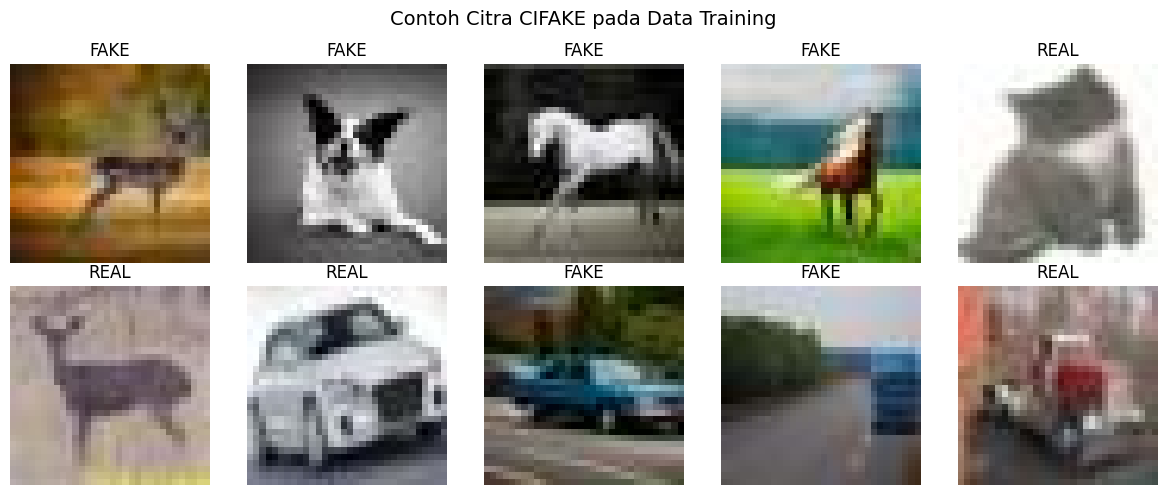

In [ ]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(images[i].numpy())

    label = CLASS_NAMES[int(labels[i].numpy())]

    plt.title(label)
    plt.axis("off")

plt.suptitle(
    "Contoh Citra CIFAKE pada Data Training",
    fontsize=14
)

plt.tight_layout()
plt.show()

# Model CNN



Model CNN digunakan untuk melakukan klasifikasi biner antara citra REAL dan FAKE.

Arsitektur yang digunakan mengikuti rancangan penelitian:

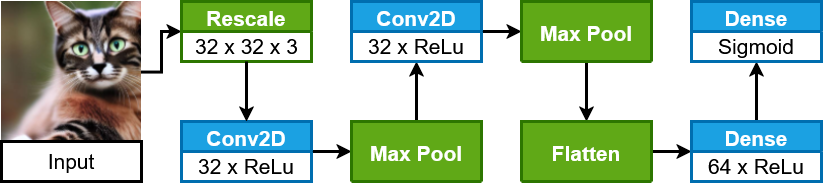

Regularisasi:
- Dropout 0.5 setelah lapisan Dense 64
- Weight decay 1e-5 pada seluruh bobot lapisan konvolusi dan dense

Optimizer:
Adam

Loss function:
Binary Cross Entropy

## Membangun CNN

In [ ]:
# Membuat fungsi untuk membangun model CNN
def build_model(seed=SEED):

    # Melakukan reset state sebelum membangun model
    tf.keras.utils.set_random_seed(seed)

    # Membuat regularisasi weight decay untuk bobot lapisan
    weight_decay_regularizer = tf.keras.regularizers.L2(WEIGHT_DECAY / 2)

    # Menyusun lapisan model secara berurutan
    model = tf.keras.Sequential(
        [
            # Menerima citra masukan berukuran 32x32 dengan 3 kanal warna
            tf.keras.layers.Input(
                shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)
            ),

            # Mengekstraksi fitur dengan 32 filter berukuran 3x3
            tf.keras.layers.Conv2D(
                filters=32,
                kernel_size=(3, 3),
                activation="relu",
                kernel_regularizer=weight_decay_regularizer,
                name="conv2d_1"
            ),

            # Mereduksi dimensi feature map dengan max pooling 2x2
            tf.keras.layers.MaxPooling2D(
                pool_size=(2, 2),
                name="maxpool_1"
            ),

            # Mengekstraksi fitur lanjutan dengan 32 filter berukuran 3x3
            tf.keras.layers.Conv2D(
                filters=32,
                kernel_size=(3, 3),
                activation="relu",
                kernel_regularizer=weight_decay_regularizer,
                name="conv2d_2"
            ),

            # Mereduksi dimensi feature map dengan max pooling 2x2
            tf.keras.layers.MaxPooling2D(
                pool_size=(2, 2),
                name="maxpool_2"
            ),

            # Mengubah feature map menjadi vektor satu dimensi
            tf.keras.layers.Flatten(
                name="flatten"
            ),

            # Mengolah fitur dengan 64 neuron pada lapisan dense
            tf.keras.layers.Dense(
                64,
                activation="relu",
                kernel_regularizer=weight_decay_regularizer,
                name="dense_64"
            ),

            # Menonaktifkan 50% neuron dense secara acak selama pelatihan
            tf.keras.layers.Dropout(
                rate=DROPOUT_RATE,
                name="dropout"
            ),

            # Menghasilkan probabilitas kelas FAKE dengan fungsi sigmoid
            tf.keras.layers.Dense(
                1,
                activation="sigmoid",
                kernel_regularizer=weight_decay_regularizer,
                name="output"
            )
        ],
        name="cnn_cifake"
    )

    return model


# Membangun model untuk pemeriksaan arsitektur
model = build_model()

print("Model berhasil dibangun")

Model berhasil dibangun


## Verifikasi Arsitektur CNN

In [ ]:
model.summary()

print("\nJumlah Parameter Total: ")
print(f"{model.count_params():,}")

print("\nVerifikasi Arsitektur Berhasil")

Model: "cnn_cifake"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_1 (MaxPooling2D)        │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 13, 13, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_2 (MaxPooling2D)        │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 84,001 (328.13 KB)

 Trainable params: 84,001 (328.13 KB)

 Non-trainable params: 0 (0.00 B)


Jumlah Parameter Total: 
84,001

Verifikasi Arsitektur Berhasil


## Utility Evaluasi Model

In [ ]:
# Membuat fungsi untuk mengambil label dan prediksi dari seluruh dataset.
def predict_dataset(model, dataset):

    # Mengambil seluruh label aktual dari dataset.
    y_true = np.concatenate([
        labels.numpy().astype(int).ravel()
        for _, labels in dataset
    ])

    # Menghasilkan probabilitas prediksi model.
    y_prob = model.predict(
        dataset,
        verbose=0
    ).ravel()

    # Mengubah probabilitas menjadi kelas menggunakan threshold 0.5.
    y_pred = (
        y_prob >= 0.5
    ).astype(int)

    # Mengembalikan label aktual, probabilitas, dan prediksi.
    return y_true, y_prob, y_pred


# Membuat fungsi untuk mengevaluasi model.
def evaluate_model(model, dataset, split_name="Test"):

    # Mengevaluasi loss dan accuracy pada dataset.
    evaluation = model.evaluate(
        dataset,
        verbose=0,
        return_dict=True
    )

    # Mengambil label aktual dan prediksi model.
    y_true, y_prob, y_pred = predict_dataset(
        model,
        dataset
    )

    # Menghitung precision.
    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # Menghitung recall.
    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # Menghitung F1-score.
    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # Menghitung confusion matrix.
    cm = confusion_matrix(
        y_true,
        y_pred
    )

    # Menghitung classification report.
    report_dict = classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    # Mengubah classification report menjadi DataFrame.
    report_df = pd.DataFrame(report_dict).T

    # Menyimpan seluruh hasil evaluasi.
    results = {
        "Split": split_name,
        "Loss": float(evaluation["loss"]),
        "Accuracy": float(evaluation["accuracy"]),
        "Precision": float(precision),
        "Recall": float(recall),
        "F1-score": float(f1),
        "y_true": y_true,
        "y_prob": y_prob,
        "y_pred": y_pred,
        "confusion_matrix": cm,
        "classification_report": report_df
    }

    # Mengembalikan hasil evaluasi.
    return results


# Membuat fungsi untuk menentukan epoch terbaik.
def get_best_epoch(history):

    # Mengambil validation loss.
    val_loss = np.array(
        history.history["val_loss"]
    )

    # Mengambil validation accuracy.
    val_accuracy = np.array(
        history.history["val_accuracy"]
    )

    # Menentukan epoch dengan validation loss minimum.
    best_loss_epoch = int(
        np.argmin(val_loss) + 1
    )

    # Menentukan epoch dengan validation accuracy maksimum.
    best_accuracy_epoch = int(
        np.argmax(val_accuracy) + 1
    )

    # Mengembalikan kedua epoch.
    return (
        best_loss_epoch,
        best_accuracy_epoch
    )

print("Utility Evaluasi Model Berhasil Dibuat")

Utility Evaluasi Model Berhasil Dibuat


# Konfigurasi *Learning Rate Range Test*



Learning Rate Range Test digunakan untuk memperoleh rentang learning rate yang
akan digunakan oleh Cyclical Learning Rate.

Rancangan:

- Start learning rate = 1e-10
- End learning rate = 1e-1
- Durasi = 5 epoch
- Kenaikan learning rate dilakukan secara eksponensial melalui faktor pengali q.
- Loss dicatat pada setiap batch.

Hasil pengujian kemudian digunakan untuk menentukan:
- base_lr: titik ketika loss mulai menurun secara konsisten
- max_lr: akhir rentang penurunan stabil, sebelum loss meningkat

## Menjalankan Learning Rate Range Test

In [ ]:
# Membersihkan session tensorflow dari model atau graph sebelumnya
tf.keras.backend.clear_session()

# Menetapkan seed untuk reproduktifitas
tf.keras.utils.set_random_seed(SEED)

# Memastikan folder hasil eksperimen tersedia
RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Membuat dataset training khusus LRRT
train_ds_lrrt = make_dataset(
    train_paths,
    train_labels,
    shuffle=True,
    seed=SEED,
    cache=False
)

# Menghitung jumlah batch dalam satu epoch
steps_per_epoch = math.ceil(len(train_paths) / BATCH_SIZE)

# Menghitung jumlah seluruh langkah pembaruan LRRT (N)
N = LRRT_EPOCHS * steps_per_epoch

# Memastikan jumlah langkah cukup untuk menghitung faktor pengali
if N < 2:
    raise RuntimeError("Jumlah total step LRRT harus lebih dari 1.")

# Menghitung faktor pengali learning rate secara eksponensial (Persamaan 2.8)
q = (LRRT_END / LRRT_START) ** (1 / (N - 1))

# Menampilkan konfigurasi LRRT
print("LEARNING RATE RANGE TEST\n")
print(f"Start LR          : {LRRT_START:.2e}")
print(f"End LR            : {LRRT_END:.2e}")
print(f"Epoch             : {LRRT_EPOCHS}")
print(f"Steps / epoch     : {steps_per_epoch:,}")
print(f"Total steps (N)   : {N:,}")
print(f"Multiplier (q)    : {q:.8f}")

# Membuat model khusus untuk LRRT dengan arsitektur yang sama
model_lrrt = build_model(seed=SEED)

# Membuat optimizer Adam dengan learning rate awal LRRT
optimizer_lrrt = tf.keras.optimizers.Adam(learning_rate=LRRT_START)

# Membuat fungsi loss Binary Cross Entropy
bce_loss = tf.keras.losses.BinaryCrossentropy()

# Menyiapkan tempat penyimpanan learning rate setiap batch
lr_values = []

# Menyiapkan tempat penyimpanan loss setiap batch
raw_loss_values = []

# Menyiapkan tempat penyimpanan rata-rata loss setiap epoch
epoch_loss_summary = []

# Menetapkan learning rate awal pengujian
current_lr = LRRT_START

# Menyiapkan penghitung langkah pembaruan
global_step = 0

# Menyiapkan penanda jika pelatihan dihentikan karena loss tidak valid
training_stopped = False

print("\nMemulai Learning Rate Range Test...")

# Menjalankan LRRT sebanyak jumlah epoch yang ditetapkan
for epoch in range(LRRT_EPOCHS):

    # Menyiapkan tempat penyimpanan loss pada epoch berjalan
    epoch_raw_losses = []

    # Memproses setiap batch pada data training
    for batch_images, batch_labels in train_ds_lrrt:

        # Menambah penghitung langkah pembaruan
        global_step += 1

        # Memasang learning rate saat ini ke optimizer
        optimizer_lrrt.learning_rate.assign(current_lr)

        # Mengubah bentuk label agar sesuai dengan keluaran model
        batch_labels = tf.reshape(batch_labels, (-1, 1))

        # Merekam operasi untuk menghitung gradien
        with tf.GradientTape() as tape:

            # Menghasilkan prediksi model pada batch saat ini
            predictions = model_lrrt(batch_images, training=True)

            # Menghitung loss antara label aktual dan prediksi
            prediction_loss = bce_loss(batch_labels, predictions)

            # Menambahkan penalti weight decay agar sama dengan loss pada pelatihan utama
            loss = prediction_loss + tf.add_n(model_lrrt.losses)

        # Menghitung gradien loss terhadap seluruh bobot model
        gradients = tape.gradient(loss, model_lrrt.trainable_variables)

        # Memperbarui bobot model menggunakan gradien
        optimizer_lrrt.apply_gradients(
            zip(gradients, model_lrrt.trainable_variables)
        )

        # Mengubah nilai loss menjadi bilangan python
        loss_value = float(loss.numpy())

        # Menghentikan pengujian jika loss tidak lagi bernilai valid
        if not np.isfinite(loss_value):

            print(
                f"\nTraining dihentikan pada step "
                f"{global_step} karena loss non-finite."
            )

            training_stopped = True
            break

        # Menyimpan learning rate yang digunakan pada batch ini
        lr_values.append(current_lr)

        # Menyimpan loss yang dihasilkan pada batch ini
        raw_loss_values.append(loss_value)

        # Menyimpan loss ke ringkasan epoch berjalan
        epoch_raw_losses.append(loss_value)

        # Menaikkan learning rate untuk batch berikutnya (Persamaan 2.9)
        current_lr *= q

    # Menampilkan rata-rata loss pada epoch yang telah selesai
    if epoch_raw_losses:

        # Menghitung rata-rata loss pada epoch berjalan
        epoch_mean_loss = float(np.mean(epoch_raw_losses))

        # Menyimpan rata-rata loss epoch
        epoch_loss_summary.append(epoch_mean_loss)

        print(
            f"Epoch {epoch + 1}/{LRRT_EPOCHS} "
            f"| mean loss = {epoch_mean_loss:.6f} "
            f"| last lr = {lr_values[-1]:.2e}"
        )

    # Menghentikan seluruh pengujian jika loss tidak valid
    if training_stopped:
        break

print("\nLearning Rate Range Test selesai.")

# Mengubah daftar learning rate menjadi numpy array
lr_values = np.array(lr_values, dtype=np.float64)

# Mengubah daftar loss menjadi numpy array
raw_loss_values = np.array(raw_loss_values, dtype=np.float64)

# Memastikan LRRT menghasilkan data
if len(lr_values) == 0:
    raise RuntimeError("LRRT tidak menghasilkan observasi.")

# Menyusun hasil LRRT ke dalam tabel
lrrt_df = pd.DataFrame({
    "learning_rate": lr_values,
    "loss": raw_loss_values
})

# Menentukan lokasi penyimpanan hasil LRRT
lrrt_path = RESULTS_DIR / "learning_rate_range_test.csv"

# Menyimpan hasil LRRT ke file CSV
lrrt_df.to_csv(lrrt_path, index=False)

# Menampilkan ringkasan hasil LRRT
print("\nHASIL LRRT\n")
print(f"Jumlah observasi       : {len(lr_values):,}")
print(f"LR aktual yang tersapu : {lr_values.min():.2e} - {lr_values.max():.2e}")
print(f"File hasil             : {lrrt_path}")

LEARNING RATE RANGE TEST

Start LR          : 1.00e-07
End LR            : 1.00e-01
Epoch             : 5
Steps / epoch     : 2,813
Total steps (N)   : 14,065
Multiplier (q)    : 1.00098281

Memulai Learning Rate Range Test...
Epoch 1/5 | mean loss = 0.693420 | last lr = 1.58e-06
Epoch 2/5 | mean loss = 0.652418 | last lr = 2.51e-05
Epoch 3/5 | mean loss = 0.468614 | last lr = 3.98e-04
Epoch 4/5 | mean loss = 0.356316 | last lr = 6.31e-03
Epoch 5/5 | mean loss = 0.537179 | last lr = 1.00e-01

Learning Rate Range Test selesai.

HASIL LRRT

Jumlah observasi       : 14,065
LR aktual yang tersapu : 1.00e-07 - 1.00e-01
File hasil             : /content/results/learning_rate_range_test.csv


## Menentukan Base LR dan Max LR

In [ ]:
# Menyaring learning rate dan loss LRRT yang memiliki nilai valid
valid_mask = (
    np.isfinite(lr_values)
    & np.isfinite(raw_loss_values)
)

# Mengambil learning rate valid untuk analisis
analysis_lr = np.asarray(lr_values, dtype=np.float64)[valid_mask]

# Mengambil loss setiap batch yang valid untuk analisis
analysis_loss = np.asarray(raw_loss_values, dtype=np.float64)[valid_mask]

# PEMBENTUKAN SEGMEN
# Menetapkan jumlah segmen pada setiap orde besaran learning rate
SEGMENTS_PER_DECADE = 5

# Menghitung jumlah batch dalam satu segmen berdasarkan faktor pengali q (Persamaan 2.8)
batches_per_segment = int(round(np.log(10 ** (1 / SEGMENTS_PER_DECADE)) / np.log(q)))

# Menghitung jumlah segmen yang terbentuk dari seluruh hasil LRRT
segment_count = len(analysis_loss) // batches_per_segment

# Memastikan jumlah segmen cukup untuk dianalisis
if segment_count < 5:
    raise ValueError("Jumlah segmen LRRT terlalu sedikit untuk dianalisis.")

# Menghitung jumlah batch yang membentuk segmen penuh
used_batches = segment_count * batches_per_segment

# Menghitung rata-rata loss pada setiap segmen
segment_loss = (
    analysis_loss[:used_batches]
    .reshape(segment_count, batches_per_segment)
    .mean(axis=1)
)

# Mengambil learning rate awal pada setiap segmen
segment_lr = analysis_lr[:used_batches:batches_per_segment]

# Menghitung perubahan rata-rata loss antar segmen yang berurutan
loss_change = np.diff(segment_loss)

# PENENTUAN TITIK TERENDAH
# Mencari segmen dengan rata-rata loss terendah sebagai batas antara fase penurunan dan kenaikan
lowest_segment_index = int(np.argmin(segment_loss))

# Memastikan terdapat fase penurunan sebelum titik terendah
if lowest_segment_index == 0:
    raise ValueError("Tidak ditemukan penurunan loss sebelum titik terendah.")

# Memastikan terdapat fase kenaikan setelah titik terendah
if lowest_segment_index >= segment_count - 1:
    raise ValueError("Loss belum meningkat hingga akhir LRRT, perbesar LRRT_END.")

# PENENTUAN BASE_LR
# Menghitung rata-rata penurunan loss per segmen dari awal LRRT sampai titik terendah
average_drop = (segment_loss[lowest_segment_index] - segment_loss[0]) / lowest_segment_index

# Mengambil perubahan loss sebelum titik terendah
changes_before_lowest = loss_change[:lowest_segment_index]

# Mencari posisi penurunan loss terbesar sebelum titik terendah
largest_drop_index = int(np.argmin(changes_before_lowest))

# Memulai penelusuran dari posisi penurunan loss terbesar
base_segment_index = largest_drop_index

# Menelusuri mundur selama penurunan loss masih lebih besar dari rata-rata penurunan
while base_segment_index > 0 and loss_change[base_segment_index - 1] < average_drop:
    base_segment_index -= 1

# Menetapkan learning rate tepat sebelum penurunan loss yang besar sebagai BASE_LR
BASE_LR = float(segment_lr[base_segment_index])

# Mengambil rata-rata loss pada segmen BASE_LR
BASE_LR_LOSS = float(segment_loss[base_segment_index])

# PENENTUAN MAX_LR
# Mengambil perubahan loss setelah titik terendah
changes_after_lowest = loss_change[lowest_segment_index:]

# Mencari posisi kenaikan loss terbesar setelah titik terendah
largest_rise_index = lowest_segment_index + int(np.argmax(changes_after_lowest))

# Menetapkan segmen terendah, yaitu tepat sebelum loss meningkat, sebagai segmen MAX_LR
max_segment_index = lowest_segment_index

# Menetapkan learning rate tepat sebelum kenaikan loss sebagai MAX_LR
MAX_LR = float(segment_lr[max_segment_index])

# Mengambil rata-rata loss pada segmen MAX_LR
MAX_LR_LOSS = float(segment_loss[max_segment_index])

# Memastikan BASE_LR lebih kecil dari MAX_LR
if BASE_LR >= MAX_LR:
    raise ValueError("BASE_LR harus lebih kecil dari MAX_LR.")

# Menyusun tabel rata-rata loss dan perubahan loss pada setiap segmen
segment_table = pd.DataFrame({
    "Segmen": np.arange(1, segment_count + 1),
    "Learning Rate Awal": segment_lr,
    "Rata-rata Loss": segment_loss,
    "Perubahan Loss": np.append(loss_change, np.nan)
})

# Menampilkan tabel segmen sebagai dasar penentuan learning rate
display(segment_table)

# Menampilkan hasil penentuan learning rate
print("\nHASIL PENENTUAN BASE_LR DAN MAX_LR\n")
print(f"Batch per segmen          : {batches_per_segment}")
print(f"Jumlah segmen             : {segment_count}")
print(f"Rata-rata penurunan       : {average_drop:.6f}")
print(f"BASE_LR                   : {BASE_LR:.6e}")
print(f"Loss segmen BASE_LR       : {BASE_LR_LOSS:.6f}")
print(f"MAX_LR                    : {MAX_LR:.6e}")
print(f"Loss segmen MAX_LR        : {MAX_LR_LOSS:.6f}")
print(f"LR saat kenaikan terbesar : {segment_lr[largest_rise_index + 1]:.6e}")

,Segmen,Learning Rate Awal,Rata-rata Loss,Perubahan Loss
0,1,1.000000e-07,0.696311,-0.001844
1,2,1.585205e-07,0.694467,-0.000097
2,3,2.512874e-07,0.694370,-0.001102
3,4,3.983419e-07,0.693269,-0.000683
4,5,6.314534e-07,0.692586,-0.003054
5,6,1.000983e-06,0.689532,-0.003083
6,7,1.586763e-06,0.686449,-0.005373
7,8,2.515343e-06,0.681076,-0.005628
8,9,3.987334e-06,0.675448,-0.015717
9,10,6.320740e-06,0.659731,-0.031438



HASIL PENENTUAN BASE_LR DAN MAX_LR

Batch per segmen          : 469
Jumlah segmen             : 29
Rata-rata penurunan       : -0.016871
BASE_LR                   : 6.320740e-06
Loss segmen BASE_LR       : 0.659731
MAX_LR                    : 1.591446e-03
Loss segmen MAX_LR        : 0.342018
LR saat kenaikan terbesar : 1.593010e-02


## Visualisasi Penentuan Base LR dan Max LR

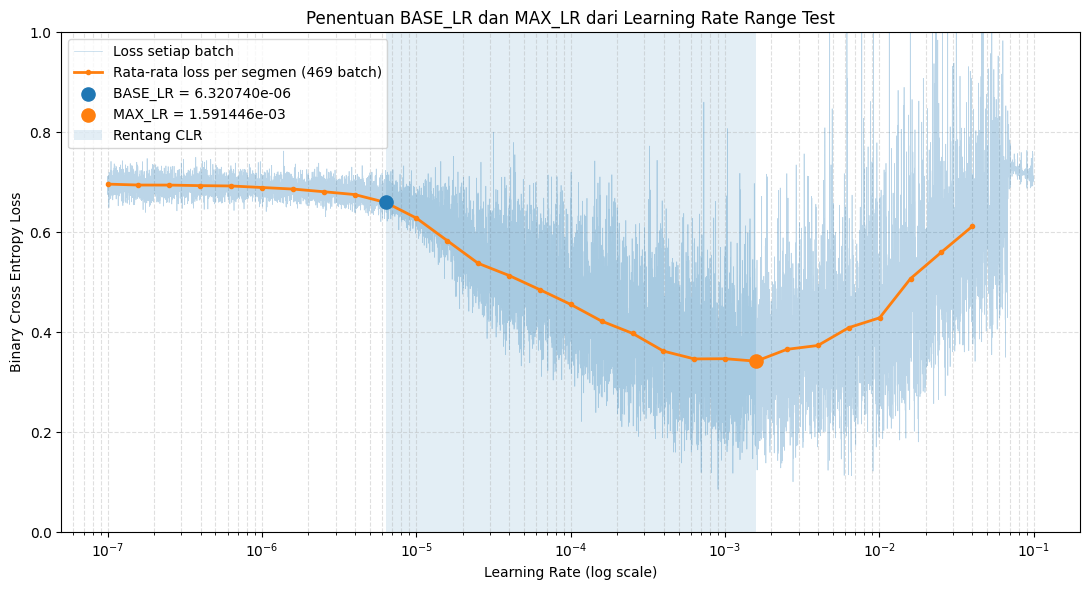

In [ ]:
# Membuat area gambar untuk kurva LRRT
plt.figure(figsize=(11, 6))

# Menggambar loss setiap batch hasil LRRT
plt.plot(
    analysis_lr,
    analysis_loss,
    linewidth=0.5,
    alpha=0.3,
    label="Loss setiap batch"
)

# Menggambar rata-rata loss setiap segmen
plt.plot(
    segment_lr,
    segment_loss,
    marker="o",
    markersize=3,
    linewidth=2,
    label=f"Rata-rata loss per segmen ({batches_per_segment} batch)"
)

# Menandai titik BASE_LR
plt.scatter(
    BASE_LR,
    BASE_LR_LOSS,
    s=90,
    zorder=5,
    label=f"BASE_LR = {BASE_LR:.6e}"
)

# Menandai titik MAX_LR
plt.scatter(
    MAX_LR,
    MAX_LR_LOSS,
    s=90,
    zorder=5,
    label=f"MAX_LR = {MAX_LR:.6e}"
)

# Mewarnai rentang learning rate yang digunakan oleh CLR
plt.axvspan(
    BASE_LR,
    MAX_LR,
    alpha=0.12,
    label="Rentang CLR"
)

# Menggunakan skala logaritmik pada sumbu learning rate
plt.xscale("log")

# Membatasi sumbu loss agar lonjakan ekstrem tidak menutupi pola kurva
plt.ylim(0, max(1.0, float(np.max(segment_loss)) * 1.1))

# Memberikan label pada kedua sumbu
plt.xlabel("Learning Rate (log scale)")
plt.ylabel("Binary Cross Entropy Loss")

# Memberikan judul grafik
plt.title("Penentuan BASE_LR dan MAX_LR dari Learning Rate Range Test")

# Menampilkan legenda dan grid
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.4)

# Menyesuaikan tata letak dan menampilkan grafik
plt.tight_layout()
plt.show()

# Eksperimen 1 - *Fixed Learning Rate*

Model CNN dilatih menggunakan *learning rate* tetap selama proses pelatihan

Konfigurasi:
- Optimizer: Adam
- Loss: *Binary Cross Entropy*
- Learning Rate: 0.001 atau 1e-3
- Epoch Maksimum: 50
- Dataset: CIFAKE
- Arsitektur: CNN yang telah ditetapkan

Model terbaik dipilih berdasarkan nilai validation loss terendah.


In [ ]:
# Membersihkan session tensorflow dari model atau graph sebelumnya
tf.keras.backend.clear_session()

# Membersihkan objek python yang sudah tidak digunakan dari memory
gc.collect()

# Menetapkan seed untuk reproduktifitas
tf.keras.utils.set_random_seed(SEED)

# Memastikan folder checkpoint tersedia
CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Menentukan lokasi file checkpoint model Fixed Learning Rate terbaik
fixed_checkpoint_path = CHECKPOINT_DIR / "fixed_best.weights.h5"

# Menghapus checkpoint lama agar tidak tercampur dengan pelatihan sebelumnya
if fixed_checkpoint_path.exists():
    fixed_checkpoint_path.unlink()

# Membuat model CNN baru menggunakan arsitektur yang sama
model_fixed = build_model(seed=SEED)

# Menyusun model dengan optimizer Adam, learning rate tetap, dan loss Binary Cross Entropy
model_fixed.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=FIXED_LR),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=["accuracy"]
)

# Membuat dataset training khusus eksperimen Fixed dengan kondisi yang sama seperti CLR
train_ds_fixed = make_dataset(
    train_paths,
    train_labels,
    shuffle=True,
    seed=SEED,
    cache=False
)

# Membuat callback untuk menyimpan model dengan validation loss terbaik
checkpoint_fixed = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(fixed_checkpoint_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
    verbose=0
)

# Menjalankan training model menggunakan dataset training dan validation
history_fixed = model_fixed.fit(
    train_ds_fixed,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[checkpoint_fixed],
    verbose=1
)

# Memuat kembali bobot model dengan validation loss terbaik
model_fixed.load_weights(fixed_checkpoint_path)

# Menentukan epoch dengan validation loss terendah
best_epoch_fixed = int(np.argmin(history_fixed.history["val_loss"]) + 1)

# Mengambil validation loss pada epoch terbaik
best_val_loss_fixed = history_fixed.history["val_loss"][best_epoch_fixed - 1]

# Mengambil validation accuracy pada epoch terbaik
best_val_accuracy_fixed = history_fixed.history["val_accuracy"][best_epoch_fixed - 1]

# Menampilkan ringkasan hasil pelatihan
print("\nHASIL PELATIHAN FIXED LEARNING RATE\n")
print(f"Learning rate       : {FIXED_LR:.2e}")
print(f"Epoch pelatihan     : {EPOCHS}")
print(f"Epoch terbaik       : {best_epoch_fixed}")
print(f"Best validation loss: {best_val_loss_fixed:.6f}")
print(f"Validation accuracy : {best_val_accuracy_fixed:.6f}")

Epoch 1/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 77s 27ms/step - accuracy: 0.8374 - loss: 0.3726 - val_accuracy: 0.8818 - val_loss: 0.2942
Epoch 2/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 73s 26ms/step - accuracy: 0.8954 - loss: 0.2664 - val_accuracy: 0.9076 - val_loss: 0.2323
Epoch 3/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 79s 28ms/step - accuracy: 0.9097 - loss: 0.2334 - val_accuracy: 0.9218 - val_loss: 0.1927
Epoch 4/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 80s 27ms/step - accuracy: 0.9186 - loss: 0.2155 - val_accuracy: 0.9131 - val_loss: 0.2108
Epoch 5/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 78s 26ms/step - accuracy: 0.9251 - loss: 0.2012 - val_accuracy: 0.9260 - val_loss: 0.1874
Epoch 6/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 77s 27ms/step - accuracy: 0.9287 - loss: 0.1939 - val_accuracy: 0.9315 - val_loss: 0.1834
Epoch 7/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 69s 24ms/step - accuracy: 0.9313 - loss: 0.1848 - val_accuracy: 0.9316 - val_loss: 0.1981
Epoch 8/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 83s 25ms/step - accuracy: 0.9351 -

## Visualisasi Loss *Fixed Learning Rate*

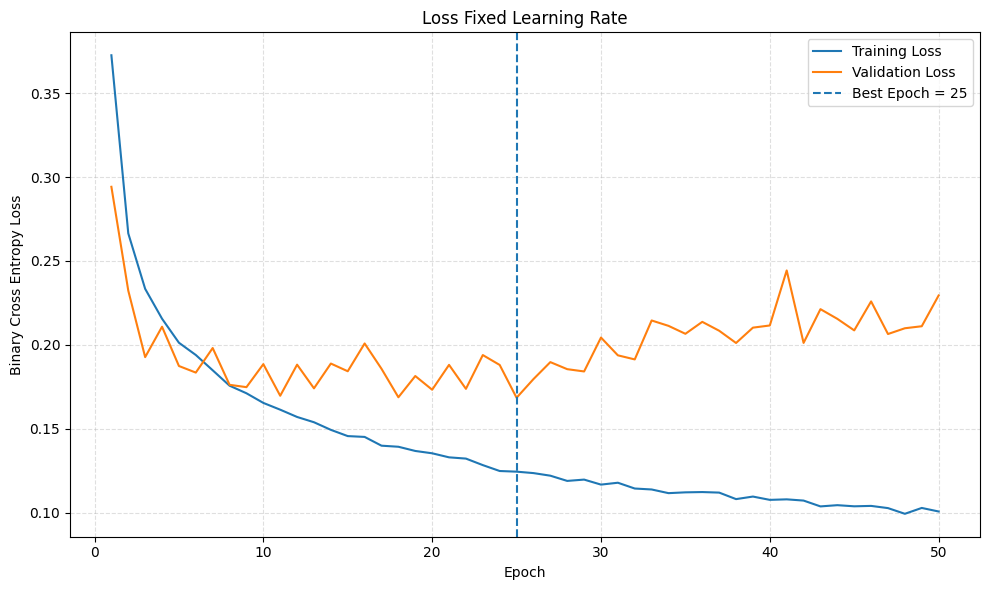

In [ ]:
# Membuat nomor epoch untuk sumbu horizontal
epochs_range = range(
    1,
    len(history_fixed.history["loss"]) + 1
)

# Membuat area gambar untuk kurva loss
plt.figure(figsize=(10, 6))

# Menggambar training loss setiap epoch
plt.plot(
    epochs_range,
    history_fixed.history["loss"],
    label="Training Loss"
)

# Menggambar validation loss setiap epoch
plt.plot(
    epochs_range,
    history_fixed.history["val_loss"],
    label="Validation Loss"
)

# Menandai posisi epoch terbaik berdasarkan validation loss
plt.axvline(
    best_epoch_fixed,
    linestyle="--",
    label=f"Best Epoch = {best_epoch_fixed}"
)

# Memberikan label sumbu dan judul grafik
plt.xlabel("Epoch")
plt.ylabel("Binary Cross Entropy Loss")
plt.title("Loss Fixed Learning Rate")

# Menampilkan legenda dan grid
plt.legend()
plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

# Menyesuaikan tata letak dan menampilkan grafik
plt.tight_layout()
plt.show()

## Visualisasi Accuracy Fixed Learning Rate

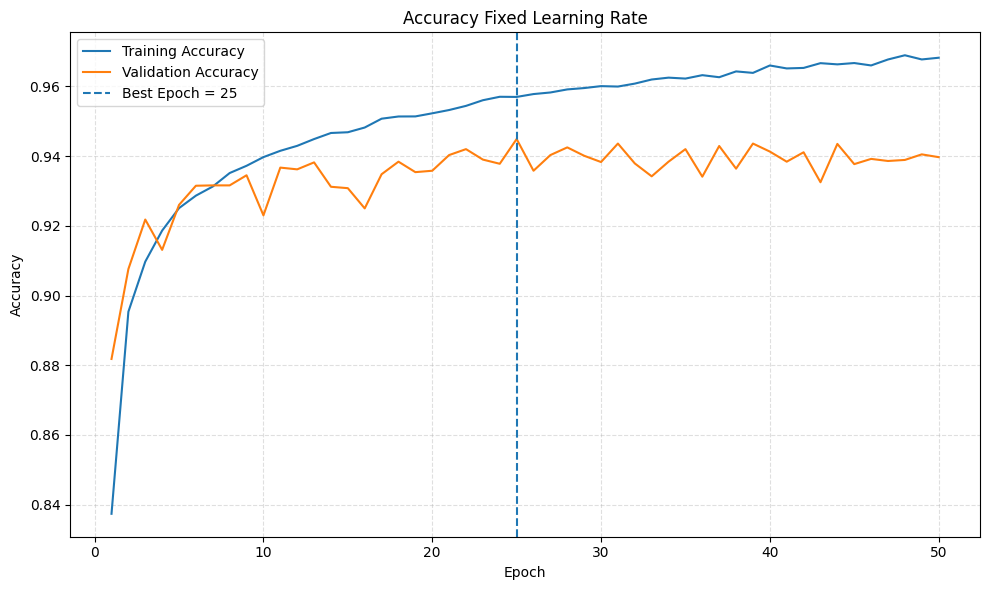

In [ ]:
# Membuat area gambar untuk kurva accuracy
plt.figure(figsize=(10, 6))

# Menggambar training accuracy setiap epoch
plt.plot(
    epochs_range,
    history_fixed.history["accuracy"],
    label="Training Accuracy"
)

# Menggambar validation accuracy setiap epoch
plt.plot(
    epochs_range,
    history_fixed.history["val_accuracy"],
    label="Validation Accuracy"
)

# Menandai posisi epoch terbaik berdasarkan validation loss
plt.axvline(
    best_epoch_fixed,
    linestyle="--",
    label=f"Best Epoch = {best_epoch_fixed}"
)

# Memberikan label sumbu dan judul grafik
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Fixed Learning Rate")

# Menampilkan legenda dan grid
plt.legend()
plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

# Menyesuaikan tata letak dan menampilkan grafik
plt.tight_layout()
plt.show()

## Evaluasi Fixed Learning Rate pada Data Testing

In [ ]:
# Menghitung loss model terbaik pada data testing
test_results_fixed = model_fixed.evaluate(
    test_ds,
    verbose=0,
    return_dict=True
)

# Menyiapkan tempat penyimpanan label aktual
y_true_fixed = []

# Menyiapkan tempat penyimpanan probabilitas prediksi
y_probability_fixed = []

# Memprediksi setiap batch pada data testing
for batch_images, batch_labels in test_ds:

    # Menghasilkan probabilitas prediksi untuk batch saat ini
    batch_probability = model_fixed.predict(
        batch_images,
        verbose=0
    ).reshape(-1)

    # Menyimpan label aktual batch saat ini
    y_true_fixed.extend(
        batch_labels.numpy().astype(int)
    )

    # Menyimpan probabilitas prediksi batch saat ini
    y_probability_fixed.extend(
        batch_probability
    )

# Mengubah label aktual menjadi numpy array
y_true_fixed = np.array(y_true_fixed)

# Mengubah probabilitas prediksi menjadi numpy array
y_probability_fixed = np.array(y_probability_fixed)

# Mengubah probabilitas menjadi kelas menggunakan ambang keputusan 0,5
y_pred_fixed = (y_probability_fixed >= 0.5).astype(int)

# Menghitung accuracy pada data testing
fixed_accuracy = accuracy_score(
    y_true_fixed,
    y_pred_fixed
)

# Menghitung precision pada data testing
fixed_precision = precision_score(
    y_true_fixed,
    y_pred_fixed,
    zero_division=0
)

# Menghitung recall pada data testing
fixed_recall = recall_score(
    y_true_fixed,
    y_pred_fixed,
    zero_division=0
)

# Menghitung F1-score pada data testing
fixed_f1 = f1_score(
    y_true_fixed,
    y_pred_fixed,
    zero_division=0
)

# Mengambil loss pada data testing
fixed_test_loss = test_results_fixed["loss"]

# Menampilkan hasil evaluasi pada data testing
print("HASIL EVALUASI FIXED LEARNING RATE\n")
print(f"Test Loss     : {fixed_test_loss:.6f}")
print(f"Test Accuracy : {fixed_accuracy:.6f}")
print(f"Test Precision: {fixed_precision:.6f}")
print(f"Test Recall   : {fixed_recall:.6f}")
print(f"Test F1-Score : {fixed_f1:.6f}")

HASIL EVALUASI FIXED LEARNING RATE

Test Loss     : 0.180479
Test Accuracy : 0.940600
Test Precision: 0.945051
Test Recall   : 0.935600
Test F1-Score : 0.940302


## Classification Report dan Confusion Matrix Fixed Learning Rate

CLASSIFICATION REPORT

              precision    recall  f1-score   support

        REAL     0.9362    0.9456    0.9409     10000
        FAKE     0.9451    0.9356    0.9403     10000

    accuracy                         0.9406     20000
   macro avg     0.9406    0.9406    0.9406     20000
weighted avg     0.9406    0.9406    0.9406     20000

CONFUSION MATRIX

[[9456  544]
 [ 644 9356]]


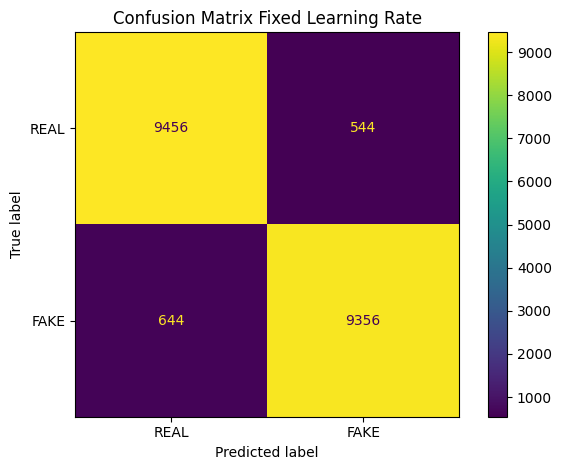

In [ ]:
# Menampilkan judul classification report
print("CLASSIFICATION REPORT\n")

# Menampilkan precision, recall, F1-score, dan support setiap kelas
print(
    classification_report(
        y_true_fixed,
        y_pred_fixed,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

# Menghitung confusion matrix dari label aktual dan prediksi
confusion_fixed = confusion_matrix(
    y_true_fixed,
    y_pred_fixed
)

# Menampilkan confusion matrix dalam bentuk angka
print("CONFUSION MATRIX\n")
print(confusion_fixed)

# Menggambar confusion matrix dengan angka bulat
ConfusionMatrixDisplay(
    confusion_matrix=confusion_fixed,
    display_labels=CLASS_NAMES
).plot(values_format="d")

# Memberikan judul pada confusion matrix
plt.title("Confusion Matrix Fixed Learning Rate")

# Menyesuaikan tata letak dan menampilkan grafik
plt.tight_layout()
plt.show()

## Menyimpan hasil Fixed Learning Rate

In [ ]:
# Mengambil seluruh riwayat pelatihan Fixed Learning Rate
fixed_history = pd.DataFrame(history_fixed.history)

# Menambahkan nomor epoch sebagai kolom pertama
fixed_history.insert(
    0,
    "Epoch",
    np.arange(1, len(fixed_history) + 1)
)

# Menambahkan nama strategi sebagai kolom pertama
fixed_history.insert(
    0,
    "Strategy",
    "Fixed Learning Rate"
)

# Menandai epoch dengan validation loss terbaik
fixed_history["Best Epoch"] = (
    fixed_history["Epoch"] == best_epoch_fixed
)

# Menampilkan seluruh riwayat pelatihan
display(fixed_history)

# Menyimpan seluruh riwayat setiap epoch ke file CSV
fixed_history.to_csv(
    RESULTS_DIR / "fixed_training_history.csv",
    index=False
)

# Menyusun hasil evaluasi akhir pada data testing
fixed_results = pd.DataFrame([
    {
        "Strategy": "Fixed Learning Rate",
        "Best Epoch": best_epoch_fixed,
        "Test Loss": fixed_test_loss,
        "Test Accuracy": fixed_accuracy,
        "Test Precision": fixed_precision,
        "Test Recall": fixed_recall,
        "Test F1-Score": fixed_f1
    }
])

# Menampilkan hasil evaluasi akhir
display(fixed_results)

# Menyimpan hasil evaluasi akhir ke file CSV
fixed_results.to_csv(
    RESULTS_DIR / "fixed_test_results.csv",
    index=False
)

,Strategy,Epoch,accuracy,loss,val_accuracy,val_loss,Best Epoch
0,Fixed Learning Rate,1,0.848522,0.342096,0.8974,0.251683,False
1,Fixed Learning Rate,2,0.907422,0.229562,0.9201,0.202456,False
2,Fixed Learning Rate,3,0.921100,0.197517,0.9219,0.189500,False
3,Fixed Learning Rate,4,0.928767,0.178117,0.9287,0.178491,False
4,Fixed Learning Rate,5,0.936233,0.162295,0.9298,0.180868,False
5,Fixed Learning Rate,6,0.940322,0.151700,0.9366,0.164982,True
6,Fixed Learning Rate,7,0.946311,0.138012,0.9304,0.181938,False
7,Fixed Learning Rate,8,0.949433,0.129950,0.9374,0.166445,False
8,Fixed Learning Rate,9,0.953822,0.118466,0.9209,0.212840,False
9,Fixed Learning Rate,10,0.957300,0.109236,0.9310,0.177653,False


,Strategy,Best Epoch,Test Loss,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,Fixed Learning Rate,6,0.166502,0.9347,0.944297,0.9239,0.933987


# Eksperimen 2 - *Cyclical Learning Rate (CLR) Triangular2*

Model CNN dilatih menggunakan **Cyclical Learning Rate mode Triangular2**

Learning rate bergerak secara suklik antara `BASE_LR` dan `MAX_LR`, sedangkan amplitudo siklus berikutnya dikurangi menjadi setengah dari siklus sebelumnya.

Eksperimen menggunakan arsitektur CNN, optimizer, fungsi loss, dataset, batch size, dan jumlah epoch yang sama dengan skenario **Fixed Learning Rate**.
Perbedaan utama terletak pada strategi learning rate

## Implementasi Schedule Triangular2

In [ ]:
# Membuat schedule learning rate Triangular2
class Triangular2LearningRate(tf.keras.optimizers.schedules.LearningRateSchedule):

    # Menginisiasi parameter schedule
    def __init__(self, base_lr, max_lr, step_size):
        super().__init__()

        # Memastikan base learning rate valid
        if base_lr <= 0:
            raise ValueError("base_lr harus lebih besar dari 0.")

        # Memastikan max learning rate lebih besar dari base learning rate
        if max_lr <= base_lr:
            raise ValueError("max_lr harus lebih besar dari base_lr.")

        # Memastikan step size valid
        if step_size <= 0:
            raise ValueError("step_size harus lebih besar dari 0.")

        # Menyimpan base learning rate
        self.base_lr = float(base_lr)

        # Menyimpan max learning rate
        self.max_lr = float(max_lr)

        # Menyimpan panjang setengah siklus
        self.step_size = float(step_size)

    # Menghitung learning rate berdasarkan training step
    def __call__(self, step):

        # Mengubah step menjadi float32
        step = tf.cast(step, tf.float32)

        # Menentukan nomor siklus (Persamaan 2.10)
        cycle = tf.floor(1.0 + step / (2.0 * self.step_size))

        # Menentukan posisi step dalam siklus (Persamaan 2.11)
        x = tf.abs(step / self.step_size - 2.0 * cycle + 1.0)

        # Membentuk pola segitiga
        scale = tf.maximum(0.0, 1.0 - x)

        # Menghitung selisih learning rate
        amplitude = self.max_lr - self.base_lr

        # Menghitung learning rate dengan amplitudo yang dibagi dua setiap siklus (Persamaan 2.13)
        learning_rate = (
            self.base_lr
            + amplitude
            * scale
            / tf.pow(2.0, cycle - 1.0)
        )

        return learning_rate

    # Menyediakan konfigurasi schedule
    def get_config(self):
        return {
            "base_lr": self.base_lr,
            "max_lr": self.max_lr,
            "step_size": self.step_size
        }


# Menampilkan konfirmasi bahwa class berhasil dibuat
print("Class Triangular2LearningRate berhasil dibuat")

Class Triangular2LearningRate berhasil dibuat


## Konfigurasi CLR

In [ ]:
# Memastikan BASE_LR dan MAX_LR sudah tersedia
if BASE_LR is None or MAX_LR is None:
    raise ValueError("BASE_LR dan MAX_LR belum ditentukan")

# Memastikan MAX_LR lebih besar dari BASE_LR
if MAX_LR <= BASE_LR:
    raise ValueError("MAX_LR harus lebih besar dari BASE_LR")

# Menghitung step size berdasarkan jumlah batch per epoch
STEP_SIZE = STEP_SIZE_MULTIPLIER * STEPS_PER_EPOCH

# Menghitung jumlah seluruh training step
TOTAL_TRAINING_STEPS = EPOCHS * STEPS_PER_EPOCH

# Membuat schedule learning rate CLR Triangular2
clr_schedule = Triangular2LearningRate(
    base_lr=BASE_LR,
    max_lr=MAX_LR,
    step_size=STEP_SIZE
)

# Menampilkan konfigurasi eksperimen
print("KONFIGURASI CLR TRIANGULAR2\n")
print(f"BASE LR              : {BASE_LR:.2e}")
print(f"MAX LR               : {MAX_LR:.2e}")
print(f"Step per epoch       : {STEPS_PER_EPOCH:,}")
print(f"Step size            : {STEP_SIZE:,}")
print(f"Full cycle           : {2 * STEP_SIZE:,} steps ({2 * STEP_SIZE // STEPS_PER_EPOCH} epoch)")
print(f"Total training steps : {TOTAL_TRAINING_STEPS:,}")
print(f"Epoch                : {EPOCHS}")

KONFIGURASI CLR TRIANGULAR2

BASE LR              : 6.32e-06
MAX LR               : 1.59e-03
Step per epoch       : 2,813
Step size            : 14,065
Full cycle           : 28,130 steps (10 epoch)
Total training steps : 140,650
Epoch                : 50


## Verifikasi Schedule Triangular2
Visualisasi ini digunakan untuk memastikan bahwa schedule menghasilkan pola learning rate sesuai karakteristik Triangular2 sebelum digunakan dalam proses pelatihan model.

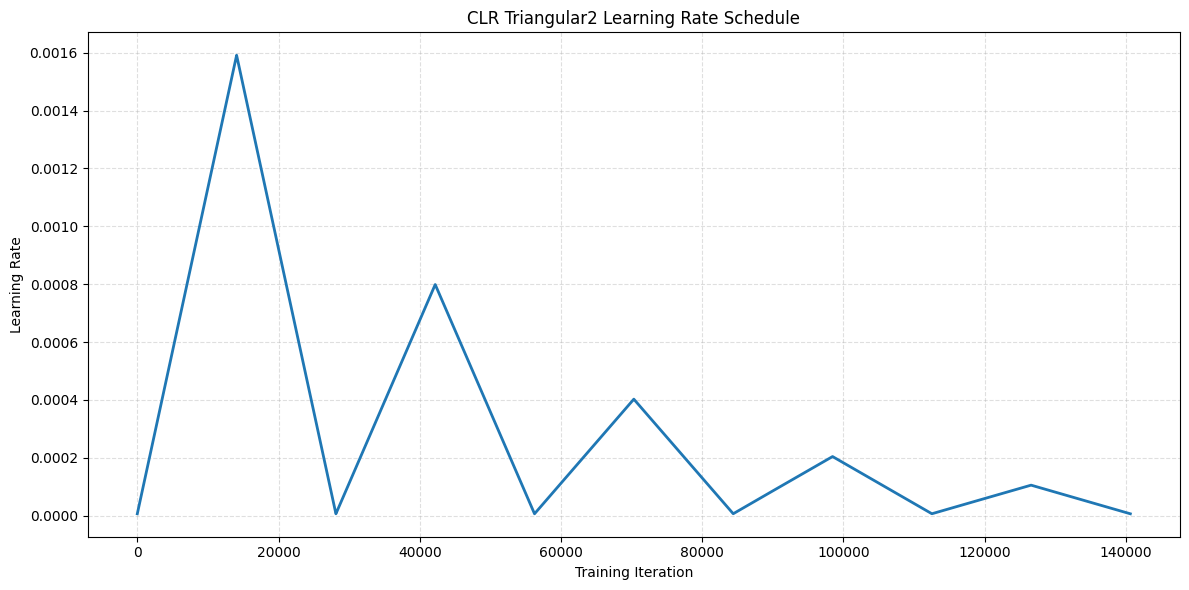


VERIFIKASI SCHEDULE TRIANGULAR2

LR minimum hasil schedule : 6.32e-06
LR maksimum hasil schedule: 1.59e-03
Base LR                   : 6.32e-06
Max LR                    : 1.59e-03


In [ ]:
# Membuat daftar training step untuk memeriksa schedule
steps_for_check = np.arange(TOTAL_TRAINING_STEPS + 1, dtype=np.int64)

# Menghitung learning rate pada setiap training step
lr_check = clr_schedule(
    tf.constant(steps_for_check, dtype=tf.float32)
).numpy()

# Membuat area gambar untuk schedule
plt.figure(figsize=(12, 6))

# Menggambar learning rate terhadap training step
plt.plot(steps_for_check, lr_check, linewidth=2)

# Memberikan label sumbu dan judul grafik
plt.xlabel("Training Iteration")
plt.ylabel("Learning Rate")
plt.title("CLR Triangular2 Learning Rate Schedule")

# Menampilkan grid
plt.grid(True, linestyle="--", which="both", alpha=0.4)

# Menyesuaikan tata letak dan menampilkan grafik
plt.tight_layout()
plt.show()

# Menampilkan hasil verifikasi schedule
print("\nVERIFIKASI SCHEDULE TRIANGULAR2\n")
print(f"LR minimum hasil schedule : {lr_check.min():.2e}")
print(f"LR maksimum hasil schedule: {lr_check.max():.2e}")
print(f"Base LR                   : {BASE_LR:.2e}")
print(f"Max LR                    : {MAX_LR:.2e}")

## Pencatatan Learning Rate selama Pelatihan

In [ ]:
# Membuat callback untuk mencatat learning rate selama pelatihan
class LearningRateHistory(tf.keras.callbacks.Callback):

    # Menginisiasi callback dengan schedule learning rate
    def __init__(self, schedule):
        super().__init__()

        # Menyimpan schedule yang digunakan dalam training
        self.schedule = schedule

        # Menyiapkan tempat penyimpanan training step
        self.steps = []

        # Menyiapkan tempat penyimpanan learning rate
        self.learning_rates = []

    # Mengatur ulang pencatatan saat training dimulai
    def on_train_begin(self, logs=None):
        self.steps = []
        self.learning_rates = []

    # Mencatat learning rate sebelum setiap batch training dijalankan
    def on_train_batch_begin(self, batch, logs=None):

        # Mengambil training step saat ini dari optimizer
        step = int(self.model.optimizer.iterations.numpy())

        # Menghitung learning rate schedule pada training step tersebut
        learning_rate = float(
            self.schedule(tf.constant(step, dtype=tf.float32)).numpy()
        )

        # Menyimpan training step yang sedang digunakan
        self.steps.append(step)

        # Menyimpan learning rate pada training step tersebut
        self.learning_rates.append(learning_rate)


# Menampilkan konfirmasi bahwa callback berhasil dibuat
print("Callback LearningRateHistory berhasil dibuat")

Callback LearningRateHistory berhasil dibuat


## Persiapan Model dan dataset CLR

In [ ]:
# Membersihkan session tensorflow dari model atau graph sebelumnya
tf.keras.backend.clear_session()

# Membersihkan objek python yang sudah tidak digunakan dari memory
gc.collect()

# Menetapkan seed untuk reproduktifitas
tf.keras.utils.set_random_seed(SEED)

# Memastikan folder checkpoint tersedia
CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Menentukan lokasi file checkpoint model CLR Triangular2 terbaik
clr_checkpoint_path = CHECKPOINT_DIR / "clr_best.weights.h5"

# Menghapus checkpoint lama agar tidak tercampur dengan pelatihan sebelumnya
if clr_checkpoint_path.exists():
    clr_checkpoint_path.unlink()

# Membuat model CNN baru menggunakan arsitektur yang sama
model_clr = build_model(seed=SEED)

# Menyusun model dengan optimizer Adam yang memakai schedule Triangular2
model_clr.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=clr_schedule),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=["accuracy"]
)

# Membuat dataset training khusus eksperimen CLR Triangular2
train_ds_clr = make_dataset(
    train_paths,
    train_labels,
    shuffle=True,
    seed=SEED,
    cache=False
)

# Membuat callback untuk mencatat learning rate pada setiap training step
lr_history_callback = LearningRateHistory(clr_schedule)

# Membuat callback untuk menyimpan model dengan validation loss terbaik
checkpoint_clr = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(clr_checkpoint_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
    verbose=0
)

print("Persiapan model dan dataset CLR Triangular2 selesai")

Persiapan model dan dataset CLR Triangular2 selesai


## Pelatihan Model dengan CLR Triangular2

In [ ]:
# Menampilkan konfigurasi pelatihan
print("Training CLR Triangular2\n")
print(f"Base LR  : {BASE_LR:.2e}")
print(f"Max LR   : {MAX_LR:.2e}")
print(f"Step size: {STEP_SIZE:,}")
print(f"Epoch    : {EPOCHS}\n")

# Menjalankan training model menggunakan dataset training dan validation
history_clr = model_clr.fit(
    train_ds_clr,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        lr_history_callback,
        checkpoint_clr
    ],
    verbose=2
)

# Memuat kembali bobot model dengan validation loss terbaik
model_clr.load_weights(clr_checkpoint_path)

print("\nModel terbaik CLR Triangular2 berhasil dimuat")

Training CLR Triangular2

Base LR  : 6.32e-06
Max LR   : 1.59e-03
Step size: 14,065
Epoch    : 50

Epoch 1/50
2813/2813 - 83s - 30ms/step - accuracy: 0.7530 - loss: 0.4903 - val_accuracy: 0.8611 - val_loss: 0.3445
Epoch 2/50
2813/2813 - 77s - 28ms/step - accuracy: 0.8658 - loss: 0.3211 - val_accuracy: 0.8905 - val_loss: 0.2689
Epoch 3/50
2813/2813 - 74s - 26ms/step - accuracy: 0.8915 - loss: 0.2724 - val_accuracy: 0.8805 - val_loss: 0.2798
Epoch 4/50
2813/2813 - 85s - 30ms/step - accuracy: 0.9029 - loss: 0.2456 - val_accuracy: 0.9152 - val_loss: 0.2111
Epoch 5/50
2813/2813 - 86s - 30ms/step - accuracy: 0.9090 - loss: 0.2347 - val_accuracy: 0.9208 - val_loss: 0.2057
Epoch 6/50
2813/2813 - 82s - 29ms/step - accuracy: 0.9162 - loss: 0.2192 - val_accuracy: 0.9279 - val_loss: 0.1947
Epoch 7/50
2813/2813 - 82s - 29ms/step - accuracy: 0.9266 - loss: 0.1972 - val_accuracy: 0.9348 - val_loss: 0.1715
Epoch 8/50
2813/2813 - 74s - 26ms/step - accuracy: 0.9361 - loss: 0.1756 - val_accuracy: 0.9240 

## Verifikasi Learning Rate Aktual dan Riwayat Pelatihan

Data learning rate yang dicatat selama training diolah menjadi data per-step dan ringkasan per-epoch. Data tersebut kemudian digabungkan dengan riwayat loss dan accuracy hasil pelatihan.

In [ ]:
# Mengubah daftar training step menjadi numpy array
clr_lr_steps = np.asarray(
    lr_history_callback.steps,
    dtype=np.int64
)

# Mengubah daftar learning rate CLR menjadi numpy array tanpa menimpa data LRRT
clr_lr_values = np.asarray(
    lr_history_callback.learning_rates,
    dtype=np.float64
)

# Mengubah training step menjadi nomor epoch
clr_lr_epochs = (clr_lr_steps // STEPS_PER_EPOCH) + 1

# Membuat tabel learning rate pada setiap training step
clr_lr_history = pd.DataFrame({
    "Epoch": clr_lr_epochs,
    "Training Step": clr_lr_steps,
    "Learning Rate": clr_lr_values
})

# Mengelompokkan learning rate berdasarkan epoch
epoch_lr_summary = (
    clr_lr_history
    .groupby("Epoch")["Learning Rate"]
    .agg(
        Learning_Rate_Min="min",
        Learning_Rate_Max="max",
        Learning_Rate_Mean="mean"
    )
    .reset_index()
)

# Mengubah history TensorFlow menjadi tabel
clr_history_df = pd.DataFrame(history_clr.history)

# Menambahkan nomor epoch sebagai kolom pertama
clr_history_df.insert(
    0,
    "Epoch",
    np.arange(1, len(clr_history_df) + 1)
)

# Menggabungkan history training dengan ringkasan learning rate per epoch
clr_history_df = clr_history_df.merge(
    epoch_lr_summary,
    on="Epoch",
    how="left"
)

# Menentukan epoch dengan validation loss terendah
clr_best_epoch = int(
    np.argmin(clr_history_df["val_loss"].to_numpy()) + 1
)

# Menandai baris yang merupakan epoch terbaik
clr_history_df["Best Epoch"] = (
    clr_history_df["Epoch"] == clr_best_epoch
)

# Menampilkan riwayat lengkap training CLR Triangular2
display(clr_history_df)

# Menampilkan ringkasan learning rate yang tercatat
print(f"\nJumlah training step yang tercatat : {len(clr_lr_history):,}")
print(f"Learning rate minimum aktual        : {clr_lr_values.min():.6e}")
print(f"Learning rate maksimum aktual       : {clr_lr_values.max():.6e}")

,Epoch,accuracy,loss,val_accuracy,val_loss,Learning_Rate_Min,Learning_Rate_Max,Learning_Rate_Mean,Best Epoch
0,1,0.752956,0.490278,0.8611,0.344546,0.000006,0.000323,0.000165,False
1,2,0.865844,0.321142,0.8905,0.268901,0.000323,0.000640,0.000482,False
2,3,0.891456,0.272363,0.8805,0.279842,0.000640,0.000957,0.000799,False
3,4,0.902889,0.245559,0.9152,0.211138,0.000957,0.001274,0.001116,False
4,5,0.909000,0.234744,0.9208,0.205723,0.001274,0.001591,0.001433,False
5,6,0.916244,0.219160,0.9279,0.194663,0.001275,0.001591,0.001433,False
6,7,0.926589,0.197184,0.9348,0.171514,0.000958,0.001274,0.001116,False
7,8,0.936067,0.175563,0.9240,0.194935,0.000640,0.000957,0.000799,False
8,9,0.944344,0.154003,0.9394,0.166342,0.000323,0.000640,0.000482,False
9,10,0.951511,0.136588,0.9445,0.152588,0.000006,0.000323,0.000165,True



Jumlah training step yang tercatat : 140,650
Learning rate minimum aktual        : 6.320740e-06
Learning rate maksimum aktual       : 1.591446e-03


## Visualisasi Learning Rate Aktual Selama Pelatihan

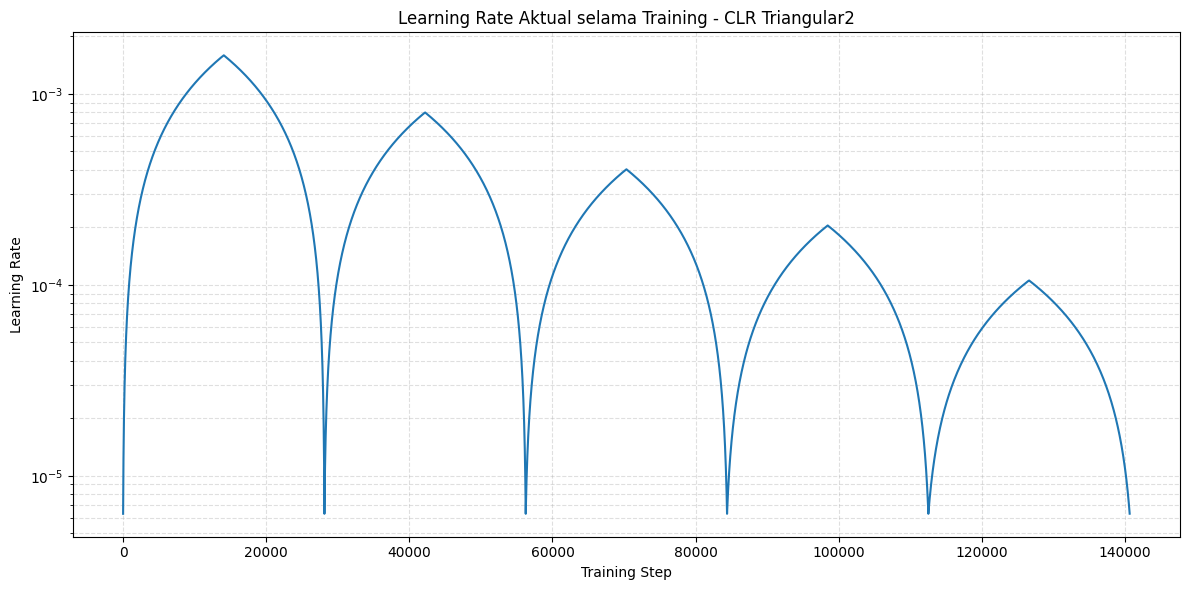

In [ ]:
# Membuat area gambar untuk learning rate aktual
plt.figure(figsize=(12, 6))

# Menggambar learning rate aktual terhadap training step
plt.plot(
    clr_lr_history["Training Step"],
    clr_lr_history["Learning Rate"],
    linewidth=1.5
)

# Memberikan label sumbu dan judul grafik
plt.xlabel("Training Step")
plt.ylabel("Learning Rate")
plt.title("Learning Rate Aktual selama Training - CLR Triangular2")

# Menggunakan skala logaritmik pada sumbu learning rate
plt.yscale("log")

# Menampilkan grid utama dan grid minor
plt.grid(True, linestyle="--", which="both", alpha=0.4)

# Menyesuaikan tata letak dan menampilkan grafik
plt.tight_layout()
plt.show()

## Visualisasi Loss dan Learning Rate Aktual

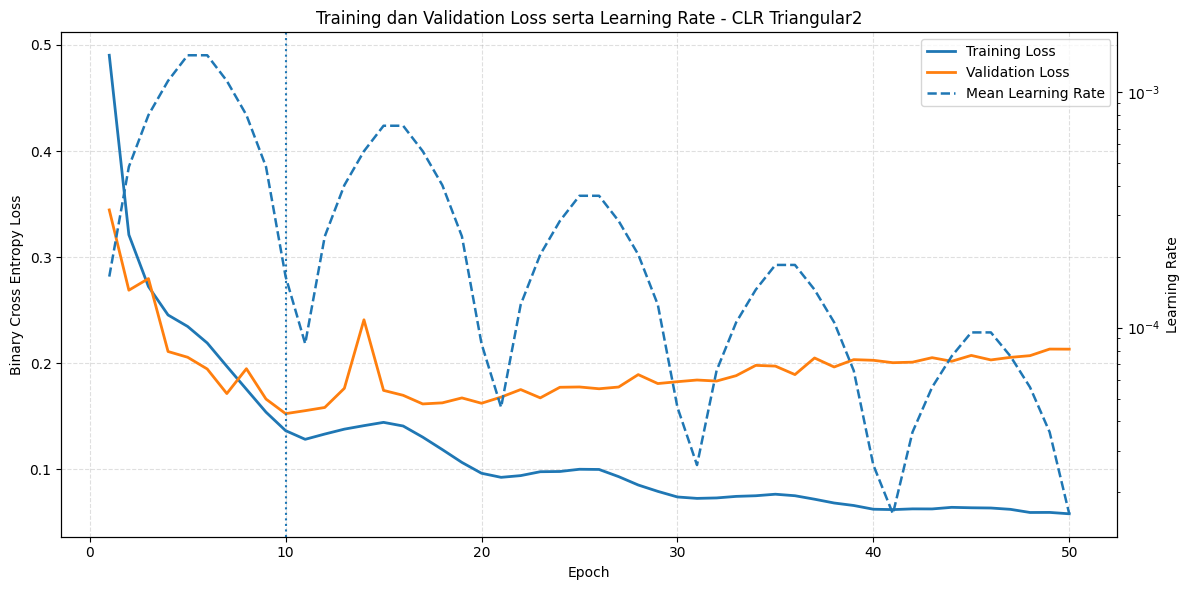

In [ ]:
# Mengambil nomor epoch dari tabel riwayat training
epochs_axis_clr = clr_history_df["Epoch"]

# Membuat area grafik utama dengan dua sumbu vertikal
fig, ax1 = plt.subplots(figsize=(12, 6))

# Menggambar training loss pada sumbu pertama
ax1.plot(
    epochs_axis_clr,
    clr_history_df["loss"],
    label="Training Loss",
    linewidth=2
)

# Menggambar validation loss pada sumbu pertama
ax1.plot(
    epochs_axis_clr,
    clr_history_df["val_loss"],
    label="Validation Loss",
    linewidth=2
)

# Memberikan label sumbu dan judul grafik
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Binary Cross Entropy Loss")
ax1.set_title("Training dan Validation Loss serta Learning Rate - CLR Triangular2")

# Menandai posisi epoch terbaik berdasarkan validation loss
ax1.axvline(clr_best_epoch, linestyle=":", linewidth=1.5)

# Membuat sumbu vertikal kedua untuk learning rate
ax2 = ax1.twinx()

# Menggambar rata-rata learning rate pada setiap epoch
ax2.plot(
    epochs_axis_clr,
    clr_history_df["Learning_Rate_Mean"],
    linestyle="--",
    linewidth=1.8,
    label="Mean Learning Rate"
)

# Memberikan label dan skala logaritmik pada sumbu learning rate
ax2.set_ylabel("Learning Rate")
ax2.set_yscale("log")

# Menggabungkan legenda dari kedua sumbu
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="best")

# Menampilkan grid pada grafik utama
ax1.grid(True, linestyle="--", alpha=0.4)

# Menyesuaikan tata letak dan menampilkan grafik
fig.tight_layout()
plt.show()

## Visualisasi Accuracy dan Learning Rate Aktual

Visualisasi ini digunakan untuk mengamati hubungan antara perubahan learning rate dengan training accuracy dan validation accuracy selama proses pelatihan model.

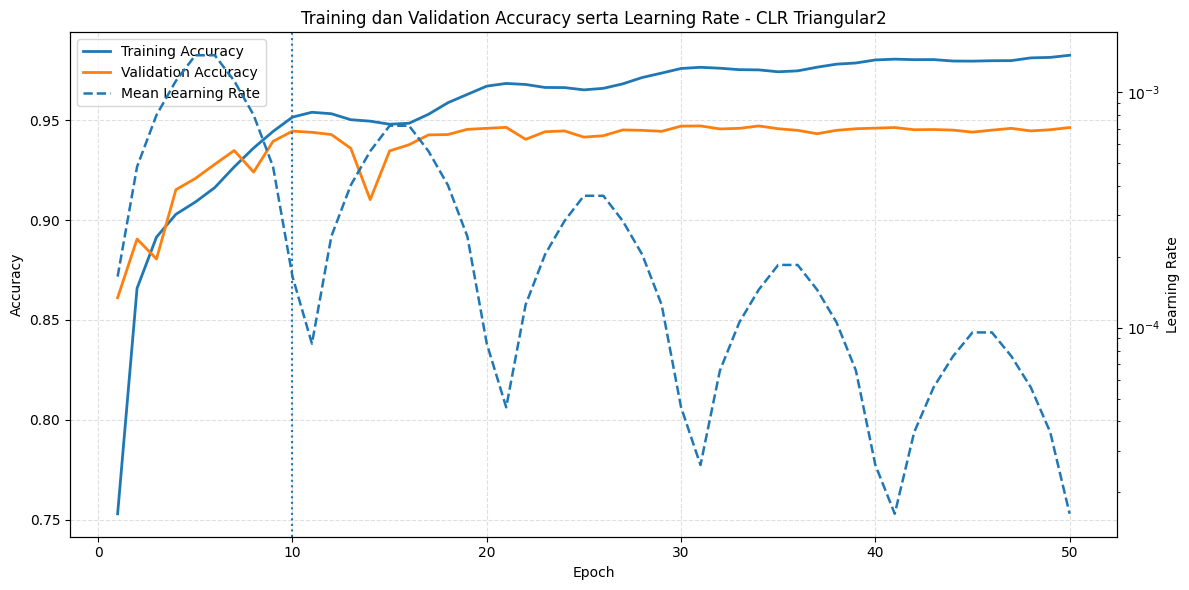

In [ ]:
# Membuat area grafik accuracy dengan dua sumbu vertikal
fig, ax1 = plt.subplots(figsize=(12, 6))

# Menggambar training accuracy pada sumbu pertama
ax1.plot(
    epochs_axis_clr,
    clr_history_df["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

# Menggambar validation accuracy pada sumbu pertama
ax1.plot(
    epochs_axis_clr,
    clr_history_df["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

# Memberikan label sumbu dan judul grafik
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy")
ax1.set_title("Training dan Validation Accuracy serta Learning Rate - CLR Triangular2")

# Menandai posisi epoch terbaik berdasarkan validation loss
ax1.axvline(clr_best_epoch, linestyle=":", linewidth=1.5)

# Membuat sumbu vertikal kedua untuk learning rate
ax2 = ax1.twinx()

# Menggambar rata-rata learning rate setiap epoch
ax2.plot(
    epochs_axis_clr,
    clr_history_df["Learning_Rate_Mean"],
    linestyle="--",
    linewidth=1.8,
    label="Mean Learning Rate"
)

# Memberikan label dan skala logaritmik pada sumbu learning rate
ax2.set_ylabel("Learning Rate")
ax2.set_yscale("log")

# Menggabungkan legenda dari kedua sumbu
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="best")

# Menampilkan grid pada grafik accuracy
ax1.grid(True, linestyle="--", alpha=0.4)

# Menyesuaikan tata letak dan menampilkan grafik
fig.tight_layout()
plt.show()

## Penentuan Epoch Terbaik CLR

Epoch terbaik ditentukan berdasarkan nilai validation loss terendah. Validation accuracy maksimum juga dicatat sebagai informasi tambahan.

In [ ]:
# Mengambil validation loss pada epoch terbaik
clr_best_val_loss = history_clr.history["val_loss"][clr_best_epoch - 1]

# Mengambil validation accuracy pada epoch terbaik
clr_best_val_accuracy = history_clr.history["val_accuracy"][clr_best_epoch - 1]

# Menentukan epoch dengan validation accuracy tertinggi
clr_best_acc_epoch = int(np.argmax(history_clr.history["val_accuracy"]) + 1)

# Mengambil nilai validation accuracy tertinggi
clr_best_acc_value = history_clr.history["val_accuracy"][clr_best_acc_epoch - 1]

# Menampilkan hasil epoch terbaik
print("EPOCH TERBAIK - CLR TRIANGULAR2\n")
print(f"Best epoch berdasarkan val_loss : {clr_best_epoch}")
print(f"Best validation loss            : {clr_best_val_loss:.6f}")
print(f"Validation accuracy pada epoch  : {clr_best_val_accuracy:.6f}")
print(f"Epoch validation accuracy max   : {clr_best_acc_epoch}")
print(f"Maximum validation accuracy     : {clr_best_acc_value:.6f}")

EPOCH TERBAIK - CLR TRIANGULAR2

Best epoch berdasarkan val_loss : 10
Best validation loss            : 0.152588
Validation accuracy pada epoch  : 0.944500
Epoch validation accuracy max   : 31
Maximum validation accuracy     : 0.947100


## Evaluasi Model CLR pada Data Testing

Model terbaik yang telah dipilih berdasarkan validation loss dievaluasi menggunakan data testing yang tidak digunakan selama proses training.

In [ ]:
# Membuat fungsi untuk memperoleh label, probabilitas, dan prediksi model
def predict_dataset(model, dataset):

    # Mengambil seluruh label aktual dari dataset
    y_true = np.concatenate([
        labels.numpy().astype(int).ravel()
        for _, labels in dataset
    ])

    # Menghasilkan probabilitas prediksi untuk seluruh data
    y_prob = model.predict(dataset, verbose=0).ravel()

    # Mengubah probabilitas menjadi kelas menggunakan ambang keputusan 0,5
    y_pred = (y_prob >= 0.5).astype(int)

    # Mengembalikan label aktual, probabilitas, dan prediksi
    return y_true, y_prob, y_pred


# Membuat fungsi untuk menghitung seluruh metrik evaluasi model
def evaluate_model(model, dataset, split_name="Test"):

    # Menghitung loss dan accuracy menggunakan Keras
    evaluation = model.evaluate(dataset, verbose=0, return_dict=True)

    # Mengambil label aktual dan prediksi model
    y_true, y_prob, y_pred = predict_dataset(model, dataset)

    # Menghitung precision
    precision = precision_score(y_true, y_pred, zero_division=0)

    # Menghitung recall
    recall = recall_score(y_true, y_pred, zero_division=0)

    # Menghitung F1-score
    f1 = f1_score(y_true, y_pred, zero_division=0)

    # Menghitung confusion matrix berdasarkan label aktual dan prediksi
    cm = confusion_matrix(y_true, y_pred)

    # Membuat classification report dalam bentuk dictionary
    report_dict = classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    # Mengembalikan seluruh hasil evaluasi dalam satu dictionary
    return {
        "Split": split_name,
        "Loss": float(evaluation["loss"]),
        "Accuracy": float(evaluation["accuracy"]),
        "Precision": float(precision),
        "Recall": float(recall),
        "F1-score": float(f1),
        "y_true": y_true,
        "y_prob": y_prob,
        "y_pred": y_pred,
        "confusion_matrix": cm,
        "classification_report": pd.DataFrame(report_dict).T
    }


# Menampilkan konfirmasi bahwa fungsi evaluasi berhasil dibuat
print("Fungsi predict_dataset dan evaluate_model berhasil dibuat")

Fungsi predict_dataset dan evaluate_model berhasil dibuat


## Evaluasi CLR

In [ ]:
# Mengevaluasi model CLR Triangular2 terbaik pada dataset testing
clr_eval = evaluate_model(
    model_clr,
    test_ds,
    split_name="Test CLR"
)

# Menampilkan hasil evaluasi pada data testing
print("HASIL TEST - CLR TRIANGULAR2\n")
print(f"Loss     : {clr_eval['Loss']:.6f}")
print(f"Accuracy : {clr_eval['Accuracy']:.6f}")
print(f"Precision: {clr_eval['Precision']:.6f}")
print(f"Recall   : {clr_eval['Recall']:.6f}")
print(f"F1-score : {clr_eval['F1-score']:.6f}")

HASIL TEST - CLR TRIANGULAR2

Loss     : 0.165321
Accuracy : 0.940350
Precision: 0.939077
Recall   : 0.941800
F1-score : 0.940436


## Classification Report dan Confusion Matrix CLR

CLASSIFICATION REPORT - CLR TRIANGULAR2



,precision,recall,f1-score,support
REAL,0.941631,0.93890,0.940263,10000.00000
FAKE,0.939077,0.94180,0.940436,10000.00000
accuracy,0.940350,0.94035,0.940350,0.94035
macro avg,0.940354,0.94035,0.940350,20000.00000
weighted avg,0.940354,0.94035,0.940350,20000.00000



CONFUSION MATRIX - CLR TRIANGULAR2

True Negative  (TN) : 9,389
False Positive (FP) : 611
False Negative (FN) : 582
True Positive  (TP) : 9,418


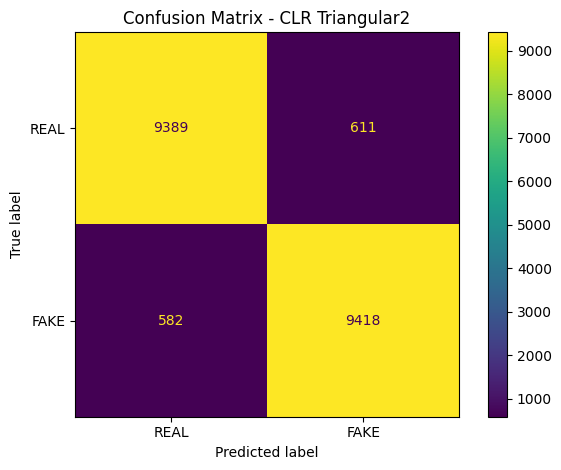

In [ ]:
# Menampilkan classification report dalam bentuk tabel
print("CLASSIFICATION REPORT - CLR TRIANGULAR2\n")
display(clr_eval["classification_report"])

# Mengambil confusion matrix dari hasil evaluasi
clr_cm = clr_eval["confusion_matrix"]

# Menguraikan confusion matrix menjadi TN, FP, FN, dan TP
tn, fp, fn, tp = clr_cm.ravel()

# Menampilkan isi confusion matrix
print("\nCONFUSION MATRIX - CLR TRIANGULAR2\n")
print(f"True Negative  (TN) : {tn:,}")
print(f"False Positive (FP) : {fp:,}")
print(f"False Negative (FN) : {fn:,}")
print(f"True Positive  (TP) : {tp:,}")

# Menggambar confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=clr_cm,
    display_labels=CLASS_NAMES
).plot(values_format="d")

# Memberikan judul pada confusion matrix
plt.title("Confusion Matrix - CLR Triangular2")

# Menyesuaikan tata letak dan menampilkan grafik
plt.tight_layout()
plt.show()

## Penyimpanan Hasil Eksperimen CLR

In [ ]:
# Menyusun metrik akhir model CLR Triangular2
clr_test_results = pd.DataFrame([
    {
        "Strategy": "CLR Triangular2",
        "Loss": clr_eval["Loss"],
        "Accuracy": clr_eval["Accuracy"],
        "Precision": clr_eval["Precision"],
        "Recall": clr_eval["Recall"],
        "F1-score": clr_eval["F1-score"],
        "Best Epoch": clr_best_epoch,
        "Best Validation Loss": clr_best_val_loss,
        "Best Validation Accuracy": clr_best_val_accuracy
    }
])

# Menyimpan metrik testing model CLR Triangular2 ke file CSV
clr_test_results.to_csv(
    RESULTS_DIR / "clr_test_results.csv",
    index=False
)

# Menyimpan history training CLR Triangular2 per epoch ke file CSV
clr_history_df.to_csv(
    RESULTS_DIR / "clr_training_history.csv",
    index=False
)

# Menyimpan learning rate pada setiap training step ke file CSV
clr_lr_history.to_csv(
    RESULTS_DIR / "clr_learning_rate_history.csv",
    index=False
)

# Menampilkan lokasi penyimpanan seluruh hasil eksperimen
print(f"Semua hasil CLR Triangular2 berhasil disimpan di: {RESULTS_DIR}")

Semua hasil CLR Triangular2 berhasil disimpan di: /content/results


# Perbandingan Fixed Learning Rate dan CLR Triangular2

Bagian ini membandingkan hasil eksperimen Fixed Learning Rate dan Cyclical Learning Rate (CLR) mode Triangular2.

Perbandingan dilakukan pada dua aspek, yaitu dinamika proses pelatihan berdasarkan validation loss dan validation accuracy, serta performa akhir model berdasarkan data testing.

Kedua skenario menggunakan arsitektur CNN, dataset, batch size, jumlah epoch, optimizer, dan fungsi loss yang sama. Perbedaan utama terletak pada strategi learning rate.

## Persiapan Data Perbandingan

Sebelum hasil dibandingkan, epoch terbaik dari masing-masing eksperimen ditentukan berdasarkan validation loss terendah. Model pada kedua skenario juga dievaluasi kembali menggunakan dataset testing dengan fungsi evaluasi yang sama.

In [ ]:
# Memastikan history Fixed Learning Rate tersedia sebelum perbandingan.
if "history_fixed" not in globals():
    # Menghentikan proses jika history Fixed Learning Rate belum tersedia.
    raise NameError(
        "history_fixed belum tersedia. Jalankan training Fixed Learning Rate terlebih dahulu."
    )

# Memastikan history CLR tersedia sebelum perbandingan.
if "history_clr" not in globals():
    # Menghentikan proses jika history CLR belum tersedia.
    raise NameError(
        "history_clr belum tersedia. Jalankan training CLR terlebih dahulu."
    )

# Memastikan model Fixed Learning Rate tersedia sebelum evaluasi.
if "model_fixed" not in globals():
    # Menghentikan proses jika model Fixed Learning Rate belum tersedia.
    raise NameError(
        "model_fixed belum tersedia. Jalankan training Fixed Learning Rate terlebih dahulu."
    )

# Memastikan model CLR tersedia sebelum evaluasi.
if "model_clr" not in globals():
    # Menghentikan proses jika model CLR belum tersedia.
    raise NameError(
        "model_clr belum tersedia. Jalankan training CLR terlebih dahulu."
    )

# Menentukan epoch dengan validation loss terendah pada Fixed Learning Rate.
fixed_best_epoch = (
    np.argmin(
        history_fixed.history["val_loss"]
    ) + 1
)

# Menentukan epoch dengan validation loss terendah pada CLR Triangular2.
clr_best_epoch = (
    np.argmin(
        history_clr.history["val_loss"]
    ) + 1
)

# Mengambil validation loss terbaik Fixed Learning Rate.
fixed_best_val_loss = (
    history_fixed.history["val_loss"][
        fixed_best_epoch - 1
    ]
)

# Mengambil validation loss terbaik CLR Triangular2.
clr_best_val_loss = (
    history_clr.history["val_loss"][
        clr_best_epoch - 1
    ]
)

# Mengambil validation accuracy pada epoch terbaik Fixed Learning Rate.
fixed_best_val_accuracy = (
    history_fixed.history["val_accuracy"][
        fixed_best_epoch - 1
    ]
)

# Mengambil validation accuracy pada epoch terbaik CLR Triangular2.
clr_best_val_accuracy = (
    history_clr.history["val_accuracy"][
        clr_best_epoch - 1
    ]
)

# Mengevaluasi kembali model Fixed Learning Rate menggunakan dataset testing.
fixed_eval = evaluate_model(
    model_fixed,
    test_ds,
    split_name="Test Fixed LR"
)

# Mengevaluasi kembali model CLR menggunakan dataset testing.
clr_eval = evaluate_model(
    model_clr,
    test_ds,
    split_name="Test CLR"
)

# Menampilkan hasil epoch terbaik dari kedua eksperimen.
print("EPOCH TERBAIK\n")

# Menampilkan epoch terbaik Fixed Learning Rate.
print(
    f"Fixed LR best epoch : "
    f"{fixed_best_epoch}"
)

# Menampilkan epoch terbaik CLR.
print(
    f"CLR best epoch      : "
    f"{clr_best_epoch}"
)

# Menampilkan validation loss terbaik Fixed Learning Rate.
print(
    f"\nFixed LR best val_loss : "
    f"{fixed_best_val_loss:.6f}"
)

# Menampilkan validation loss terbaik CLR.
print(
    f"CLR best val_loss      : "
    f"{clr_best_val_loss:.6f}"
)

# Menampilkan validation accuracy pada epoch terbaik Fixed Learning Rate.
print(
    f"\nFixed LR val_accuracy : "
    f"{fixed_best_val_accuracy:.6f}"
)

# Menampilkan validation accuracy pada epoch terbaik CLR.
print(
    f"CLR val_accuracy      : "
    f"{clr_best_val_accuracy:.6f}"
)

EPOCH TERBAIK

Fixed LR best epoch : 25
CLR best epoch      : 10

Fixed LR best val_loss : 0.168447
CLR best val_loss      : 0.152588

Fixed LR val_accuracy : 0.944900
CLR val_accuracy      : 0.944500


## Perbandingan Metrik Testing

Performa akhir kedua model dibandingkan menggunakan data testing yang tidak digunakan selama proses pelatihan. Metrik yang dibandingkan meliputi loss, accuracy, precision, recall, dan F1-score.

Nilai delta dihitung sebagai selisih antara CLR Triangular2 dan Fixed Learning Rate.

In [ ]:
# Memastikan epoch terbaik Fixed tersedia.
fixed_best_epoch = best_epoch_fixed

# Membuat tabel perbandingan metrik.
comparison = pd.DataFrame({
    "Metric": [
        "Loss",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Fixed LR": [
        fixed_eval["Loss"],
        fixed_eval["Accuracy"],
        fixed_eval["Precision"],
        fixed_eval["Recall"],
        fixed_eval["F1-score"]
    ],
    "CLR Triangular2": [
        clr_eval["Loss"],
        clr_eval["Accuracy"],
        clr_eval["Precision"],
        clr_eval["Recall"],
        clr_eval["F1-score"]
    ]
})

# Menghitung selisih CLR terhadap Fixed LR.
comparison[
    "Delta (CLR - Fixed)"
] = (
    comparison["CLR Triangular2"]
    - comparison["Fixed LR"]
)

# Menampilkan garis pembatas.
print("=" * 60)

# Menampilkan judul perbandingan.
print(
    "PERBANDINGAN HASIL EKSPERIMEN"
)

# Menampilkan garis pembatas.
print("=" * 60)

# Menampilkan tabel hasil.
display(
    comparison.style.format({
        "Fixed LR": "{:.6f}",
        "CLR Triangular2": "{:.6f}",
        "Delta (CLR - Fixed)": "{:+.6f}"
    })
)

# Menyimpan comparison ke CSV.
comparison.to_csv(
    RESULTS_DIR
    / "comparison_fixed_vs_clr.csv",
    index=False
)

PERBANDINGAN HASIL EKSPERIMEN


,Metric,Fixed LR,CLR Triangular2,Delta (CLR - Fixed)
0,Loss,0.180479,0.165321,-0.015158
1,Accuracy,0.940600,0.940350,-0.000250
2,Precision,0.945051,0.939077,-0.005974
3,Recall,0.935600,0.941800,+0.006200
4,F1-score,0.940302,0.940436,+0.000135


## Perbandingan Validation Loss

Validation loss digunakan untuk membandingkan dinamika pembelajaran kedua strategi learning rate selama proses pelatihan. Validation data tidak digunakan untuk memperbarui bobot model dan digunakan untuk memantau kemampuan generalisasi selama training.

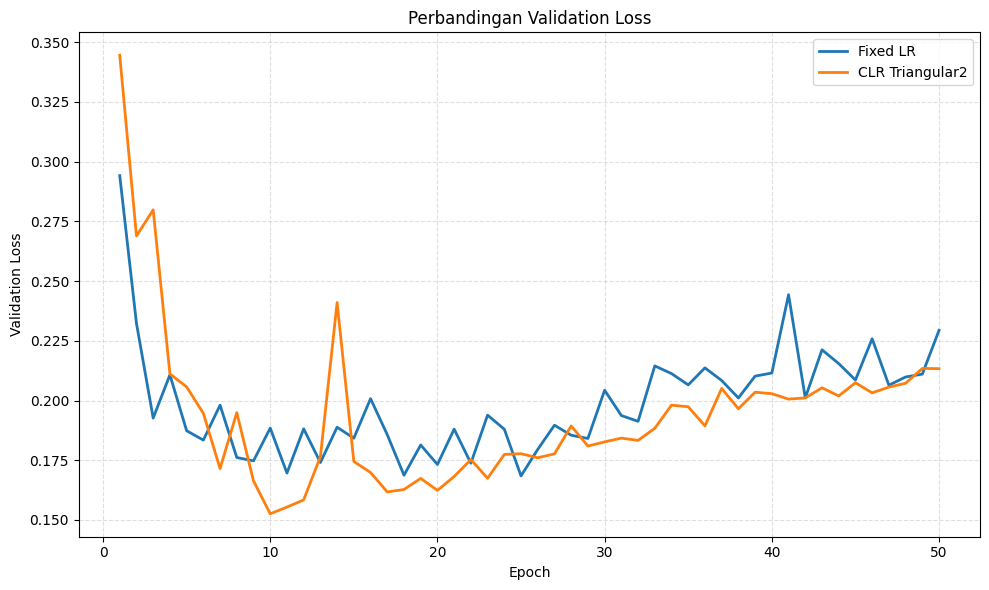

In [ ]:
# Membuat array epoch yang digunakan kedua eksperimen.
epochs_common = np.arange(
    1,
    EPOCHS + 1
)

# Membuat figure validation loss.
plt.figure(figsize=(10, 6))

# Menggambar validation loss Fixed LR.
plt.plot(
    epochs_common,
    history_fixed.history["val_loss"],
    label="Fixed LR",
    linewidth=2
)

# Menggambar validation loss CLR.
plt.plot(
    epochs_common,
    history_clr.history["val_loss"],
    label="CLR Triangular2",
    linewidth=2
)

# Memberikan label sumbu X.
plt.xlabel(
    "Epoch"
)

# Memberikan label sumbu Y.
plt.ylabel(
    "Validation Loss"
)

# Memberikan judul grafik.
plt.title(
    "Perbandingan Validation Loss"
)

# Menampilkan legenda.
plt.legend()

# Menampilkan grid.
plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

# Merapikan layout.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

## Perbandingan Validation Accuracy

Validation accuracy dibandingkan untuk melihat perkembangan kemampuan klasifikasi kedua model selama proses pelatihan.

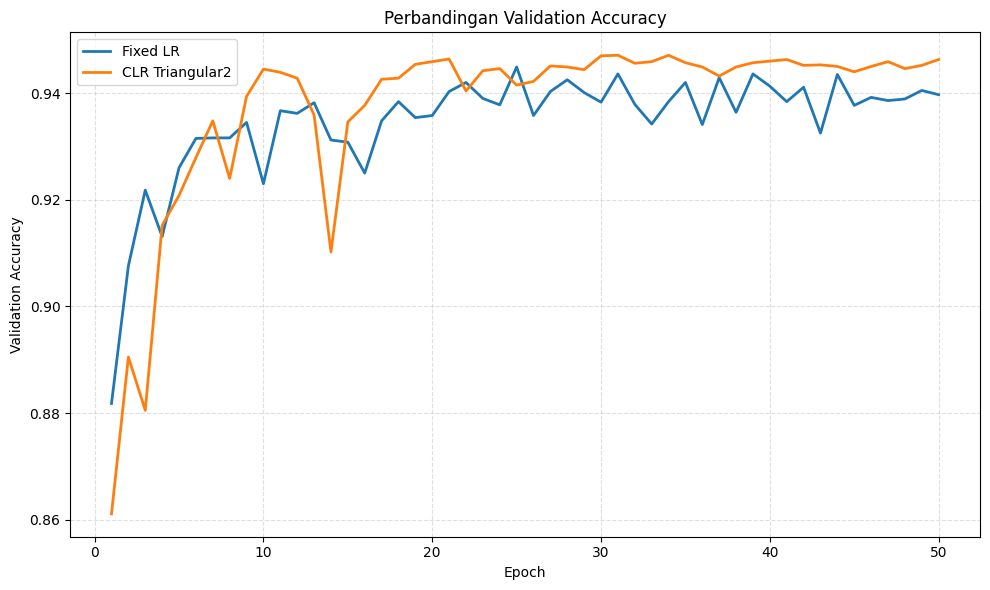

In [ ]:
# Membuat figure validation accuracy.
plt.figure(figsize=(10, 6))

# Menggambar validation accuracy Fixed LR.
plt.plot(
    epochs_common,
    history_fixed.history["val_accuracy"],
    label="Fixed LR",
    linewidth=2
)

# Menggambar validation accuracy CLR.
plt.plot(
    epochs_common,
    history_clr.history["val_accuracy"],
    label="CLR Triangular2",
    linewidth=2
)

# Memberikan label sumbu X.
plt.xlabel(
    "Epoch"
)

# Memberikan label sumbu Y.
plt.ylabel(
    "Validation Accuracy"
)

# Memberikan judul grafik.
plt.title(
    "Perbandingan Validation Accuracy"
)

# Menampilkan legenda.
plt.legend()

# Menampilkan grid.
plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

# Merapikan layout.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

## Visualisasi Perbandingan Metrik Testing

Visualisasi digunakan untuk memperlihatkan perbedaan performa akhir Fixed Learning Rate dan CLR Triangular2 pada data testing.

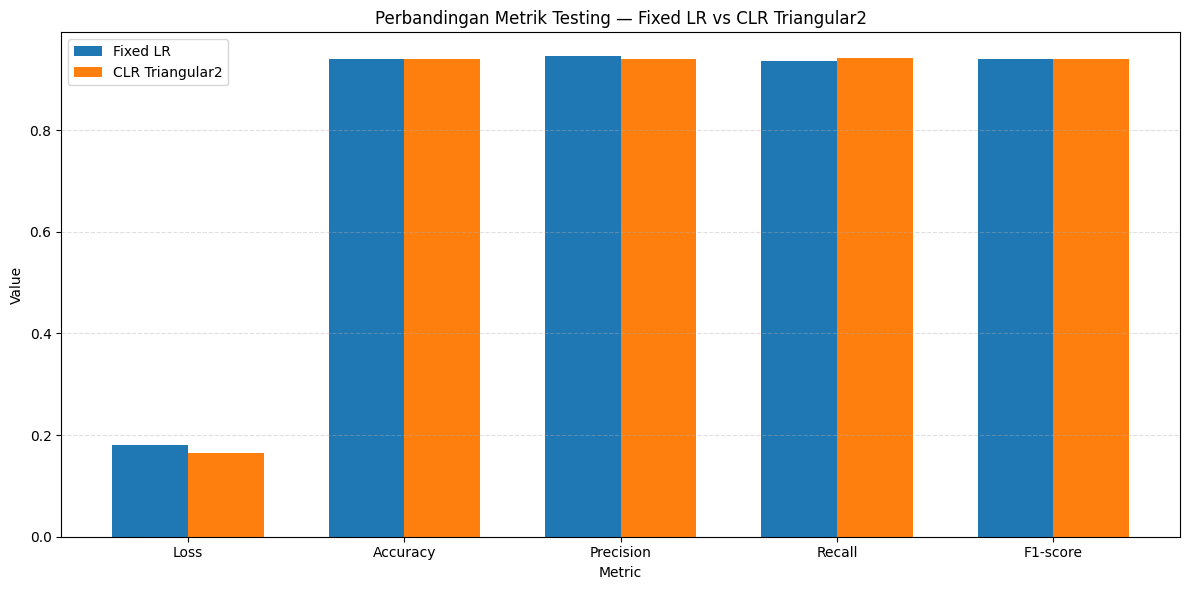

In [ ]:
# Menentukan posisi setiap metrik pada sumbu horizontal.
metric_positions = np.arange(
    len(comparison["Metric"])
)

# Menentukan lebar setiap batang.
bar_width = 0.35

# Membuat area grafik perbandingan metrik.
plt.figure(figsize=(12, 6))

# Menggambar metrik Fixed Learning Rate.
plt.bar(
    metric_positions - bar_width / 2,
    comparison["Fixed LR"],
    width=bar_width,
    label="Fixed LR"
)

# Menggambar metrik CLR Triangular2.
plt.bar(
    metric_positions + bar_width / 2,
    comparison["CLR Triangular2"],
    width=bar_width,
    label="CLR Triangular2"
)

# Mengatur posisi label metrik pada sumbu horizontal.
plt.xticks(
    metric_positions,
    comparison["Metric"]
)

# Memberikan label pada sumbu horizontal.
plt.xlabel("Metric")

# Memberikan label pada sumbu vertikal.
plt.ylabel("Value")

# Memberikan judul grafik.
plt.title(
    "Perbandingan Metrik Testing — Fixed LR vs CLR Triangular2"
)

# Menampilkan legend.
plt.legend()

# Menampilkan grid horizontal untuk membantu membaca nilai.
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

# Menyesuaikan tata letak grafik.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

# Ringkasan Eksperimen

Ringkasan eksperimen menyatukan konfigurasi utama penelitian, parameter learning rate, epoch terbaik, serta hasil testing dari Fixed Learning Rate dan CLR Triangular2.

In [ ]:
# Menyamakan nama epoch terbaik Fixed Learning Rate.
fixed_best_epoch = best_epoch_fixed

# Membuat tabel ringkasan seluruh eksperimen.
experiment_summary = pd.DataFrame({
    "Parameter": [
        "Training images",
        "Validation images",
        "Testing images",
        "Batch size",
        "Epoch maksimum",
        "Fixed learning rate",
        "LRRT start",
        "LRRT end",
        "LRRT epochs",
        "CLR base_lr",
        "CLR max_lr",
        "CLR step_size",
        "Fixed best epoch",
        "CLR best epoch",
        "Fixed test loss",
        "CLR test loss",
        "Fixed test accuracy",
        "CLR test accuracy",
        "Fixed test precision",
        "CLR test precision",
        "Fixed test recall",
        "CLR test recall",
        "Fixed test F1",
        "CLR test F1"
    ],
    "Value": [
        len(train_paths),
        len(val_paths),
        len(test_paths),
        BATCH_SIZE,
        EPOCHS,
        FIXED_LR,
        LRRT_START,
        LRRT_END,
        LRRT_EPOCHS,
        BASE_LR,
        MAX_LR,
        STEP_SIZE,
        fixed_best_epoch,
        clr_best_epoch,
        fixed_eval["Loss"],
        clr_eval["Loss"],
        fixed_eval["Accuracy"],
        clr_eval["Accuracy"],
        fixed_eval["Precision"],
        clr_eval["Precision"],
        fixed_eval["Recall"],
        clr_eval["Recall"],
        fixed_eval["F1-score"],
        clr_eval["F1-score"]
    ]
})

# Menampilkan tabel ringkasan eksperimen.
display(
    experiment_summary
)

# Menyimpan ringkasan eksperimen ke CSV.
experiment_summary.to_csv(
    RESULTS_DIR
    / "experiment_summary.csv",
    index=False
)

# Menampilkan lokasi seluruh hasil eksperimen.
print(
    f"\nSemua hasil eksperimen disimpan di: "
    f"{RESULTS_DIR}"
)

,Parameter,Value
0,Training images,9.000000e+04
1,Validation images,1.000000e+04
2,Testing images,2.000000e+04
3,Batch size,3.200000e+01
4,Epoch maksimum,5.000000e+01
5,Fixed learning rate,1.000000e-03
6,LRRT start,1.000000e-07
7,LRRT end,1.000000e-01
8,LRRT epochs,5.000000e+00
9,CLR base_lr,6.320740e-06



Semua hasil eksperimen disimpan di: /content/results


## Perbandingan Training Loss (Fixed LR vs CLR Triangular2)

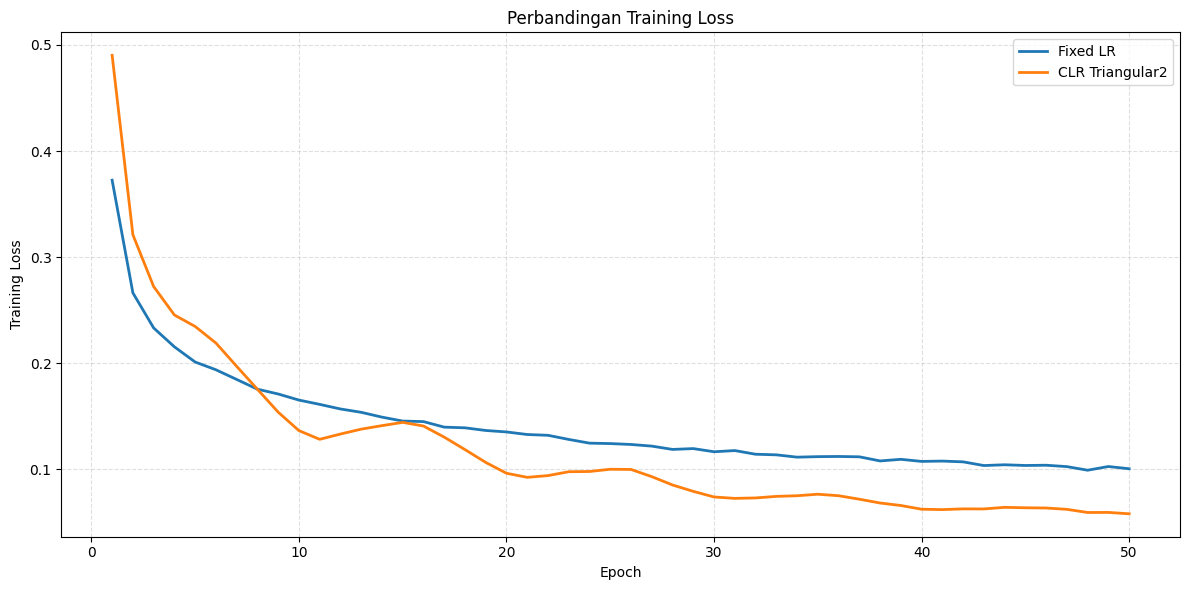

In [ ]:
# Menampilkan perbandingan Training Loss hanya untuk Fixed LR dan CLR Triangular2
plt.figure(figsize=(12, 6))

plt.plot(epochs_common, history_fixed.history["loss"], label="Fixed LR", linewidth=2)
plt.plot(epochs_common, history_clr.history["loss"], label="CLR Triangular2", linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Perbandingan Training Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## Perbandingan Validation Loss (Fixed LR vs CLR Triangular2)

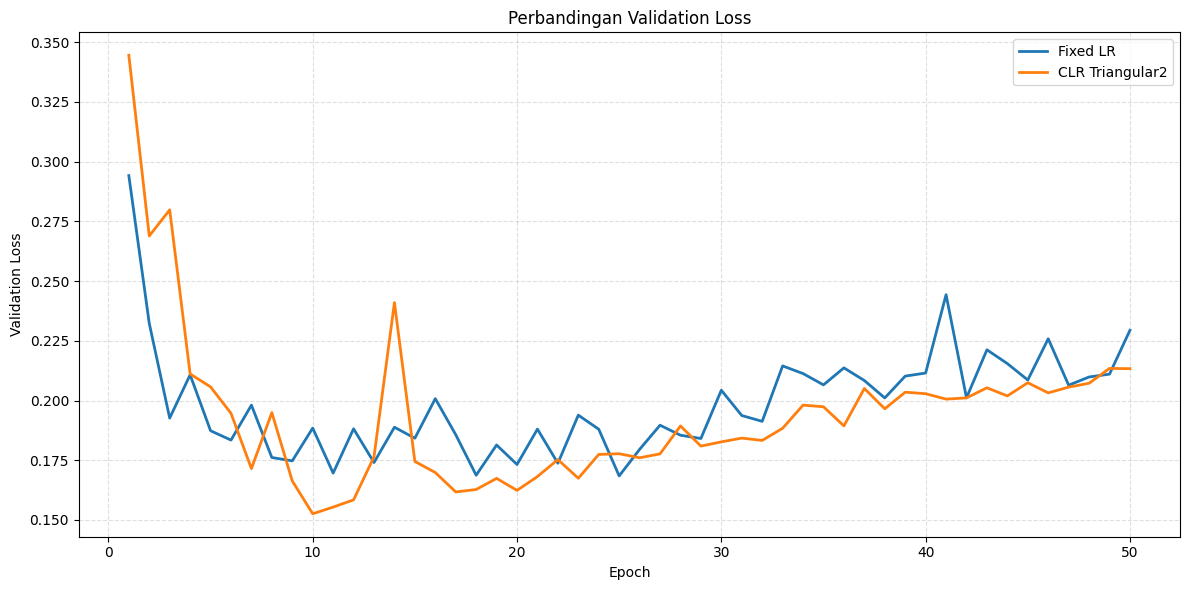

In [ ]:
# Menampilkan perbandingan Validation Loss hanya untuk Fixed LR dan CLR Triangular2
plt.figure(figsize=(12, 6))

plt.plot(epochs_common, history_fixed.history["val_loss"], label="Fixed LR", linewidth=2)
plt.plot(epochs_common, history_clr.history["val_loss"], label="CLR Triangular2", linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Perbandingan Validation Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## Perbandingan Test Loss (Fixed LR vs CLR Triangular2)

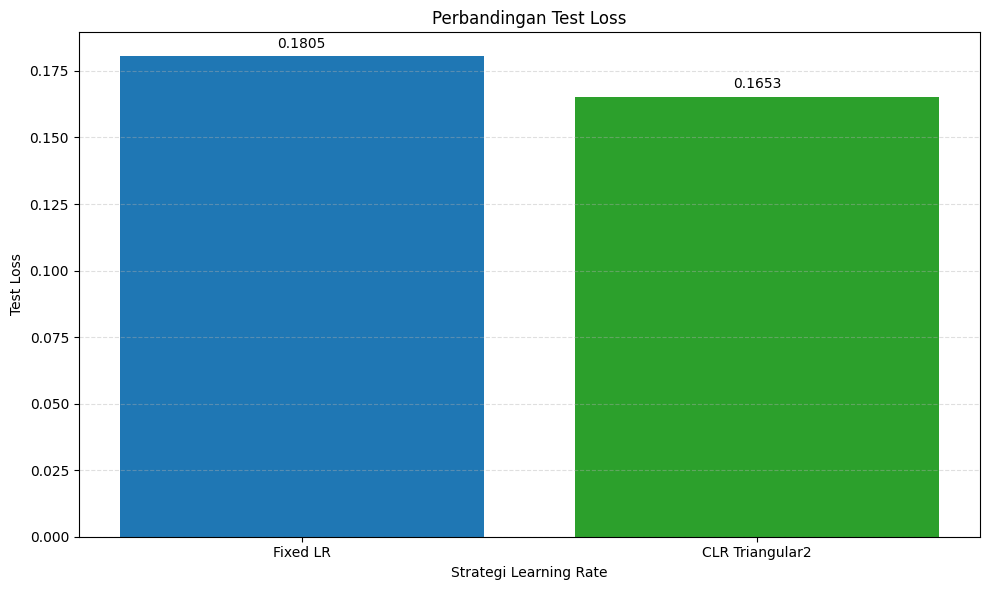

In [ ]:
# Menampilkan perbandingan Test Loss hanya untuk Fixed LR dan CLR Triangular2
strategies = ["Fixed LR", "CLR Triangular2"]
test_losses = [
    fixed_eval["Loss"],
    clr_eval["Loss"]
]

plt.figure(figsize=(10, 6))
bars = plt.bar(strategies, test_losses, color=['#1f77b4', '#2ca02c'])

# Menambahkan nilai di atas bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.002, round(yval, 4), ha='center', va='bottom')

plt.xlabel("Strategi Learning Rate")
plt.ylabel("Test Loss")
plt.title("Perbandingan Test Loss")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()